# CityFlowV2-ReID — Full Pipeline

Single notebook covering the full thesis workflow:

| Section | What it does |
|---|---|
| **1. Setup** | Mount Drive, install deps, configure paths |
| **2. Data** | Copy images to local SSD, parse XML labels, write CSVs |
| **3. Baseline Eval** | Evaluate ImageNet-pretrained ViT-B/16 (no ReID training) |
| **4. Finetuning** | Train with Supervised Contrastive loss on CityFlowV2-ReID |
| **5. Post-Finetune Eval** | Re-evaluate with finetuned weights + comparison table |

**Resumable throughout** — checkpoints and CSVs go to Drive; image copy resumes from where it left off after any disconnect.

---
Before running: **Runtime → Change runtime type → T4 GPU**

## Section 1 — Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import torch
if not torch.cuda.is_available():
    raise RuntimeError('No GPU — go to Runtime -> Change runtime type -> T4 GPU.')
DEVICE = 'cuda'
print(f'GPU  : {torch.cuda.get_device_name(0)}')
print(f'VRAM : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Mounted at /content/drive
GPU  : NVIDIA L4
VRAM : 23.7 GB


In [3]:
%%capture
!pip install opencv-python-headless tqdm
!pip install torchreid

In [4]:
# ── Colab Timeout & Memory Optimization ──────────────────────────────────────
import socket

# Increase socket timeout for slow network
socket.setdefaulttimeout(600)

# Optimize memory
import gc
gc.collect()

print('✓ Timeout & memory optimizations configured')

✓ Timeout & memory optimizations configured


In [5]:
import os

# Set this before any torch import to reduce memory fragmentation
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

CFG = {
    # --- Drive paths ---
    'drive_real_zip':   '/content/drive/MyDrive/AICity21_Track2_ReID.zip',
    'drive_sim_zip':    '/content/drive/MyDrive/AICity21_Track2_ReID_Simulation.zip',
    'drive_data':       '/content/drive/MyDrive/Thesis/AIC21_Track2_ReID',   # XMLs live here

    # --- Local SSD paths (fast I/O during training) ---
    'local_data':       '/content/cityflow_data',
    'local_sim_data':   '/content/sim_data',

    # --- Output paths (Drive, survives disconnects) ---
    'out_dir':          '/content/drive/MyDrive/Thesis',
    'checkpoint_dir':   '/content/drive/MyDrive/Thesis/checkpoints_osnet',
    'weights_out':      '/content/drive/MyDrive/Thesis/vehicle_reid_osnet.pth',

    # --- Model ---
    'model_name':       'osnet_ain_x1_0',
    'feat_dim':         512,          # OSNet output dimension
    'img_h':            256,
    'img_w':            256,

    # --- Evaluation (no_grad — larger batch is fine) ---
    'eval_batch':       128,
    'num_workers':      2,            # T4 Colab recommends ≤2
    'eval_hold_frac':   0.20,

    # --- PK Sampling: batch = P * K ---
    # P=8, K=4 → batch=32.  Keeps activation memory well under 15 GB T4 limit.
    # (P=32 caused OOM: 128 imgs × 256×256 backprop activations > 14 GB)
    'P': 8,
    'K': 4,

    # --- Training ---
    'num_epochs':       40,
    'lr':               3e-4,
    'weight_decay':     5e-4,
    'warmup_epochs':    5,
    'temp':             0.07,
    'proj_dim':         128,
    'val_split':        0.15,

    # --- Resumability ---
    'resume':     True,
    'keep_ckpts': 3,
}

for d in [CFG['local_data'], CFG['local_sim_data'],
          CFG['out_dir'], CFG['checkpoint_dir']]:
    os.makedirs(d, exist_ok=True)

# Derived paths
CFG['train_csv']     = os.path.join(CFG['out_dir'], 'osnet_train.csv')
CFG['cross_cam_csv'] = os.path.join(CFG['out_dir'], 'osnet_crosscam_eval.csv')
CFG['results_out']   = os.path.join(CFG['out_dir'], 'osnet_eval_results.csv')

print('Config ready.')
print(f"  Real ZIP   : {CFG['drive_real_zip']}")
print(f"  Sim  ZIP   : {CFG['drive_sim_zip']}")
print(f"  Model      : {CFG['model_name']}  ({CFG['feat_dim']}-dim, {CFG['img_h']}×{CFG['img_w']})")
print(f"  Batch size : {CFG['P']}×{CFG['K']}={CFG['P']*CFG['K']} (PK sampler)")

Config ready.
  Real ZIP   : /content/drive/MyDrive/AICity21_Track2_ReID.zip
  Sim  ZIP   : /content/drive/MyDrive/AICity21_Track2_ReID_Simulation.zip
  Model      : osnet_ain_x1_0  (512-dim, 256×256)
  Batch size : 8×4=32 (PK sampler)


## Section 2 — Data Preparation

In [6]:
import shutil
import zipfile
from pathlib import Path
from tqdm.notebook import tqdm

COPY_MARKER    = '.extract_complete'
LOCAL_REAL_ZIP = '/content/AICity21_Track2_ReID.zip'
LOCAL_SIM_ZIP  = '/content/AICity21_Track2_ReID_Simulation.zip'


def ensure_local_zip(drive_path, local_path, label):
    if os.path.exists(local_path):
        print(f'{label}: already on SSD ({os.path.getsize(local_path)/1e9:.2f} GB). Skipping.')
        return
    print(f'Copying {label} from Drive to SSD (one-time)...')
    shutil.copy(drive_path, local_path)
    print(f'{label}: done  ({os.path.getsize(local_path)/1e9:.2f} GB)')


def extract_split_resumable(zip_path, dst_dir, split_keyword, label=None):
    """Extract images whose zip path contains split_keyword into dst_dir (resumable)."""
    dst_dir = Path(dst_dir)
    marker  = dst_dir / COPY_MARKER
    lbl     = label or dst_dir.name

    if marker.exists():
        n = sum(1 for _ in dst_dir.rglob('*.jpg'))
        print(f'  {lbl}: already extracted ({n} images). Skipping.')
        return

    dst_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        members = [m for m in zf.namelist()
                   if f'/{split_keyword}/' in m and m.endswith('.jpg')]
        for m in tqdm(members, desc=f'  {lbl}', unit='file', leave=False):
            zf.extract(m, dst_dir)
    marker.touch()
    n = sum(1 for _ in dst_dir.rglob('*.jpg'))
    print(f'  {lbl}: {n} images extracted.')


def extract_xml_from_zip(zip_path, dst_dir):
    """Extract all XML files from a ZIP to dst_dir (flat)."""
    dst_dir = Path(dst_dir)
    dst_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        xmls = [m for m in zf.namelist() if m.endswith('.xml')]
        for m in xmls:
            fname = Path(m).name
            (dst_dir / fname).write_bytes(zf.read(m))
            print(f'  Extracted XML: {fname}')


# ── Real CityFlowV2 ────────────────────────────────────────────────────────────
print('=== Real data (CityFlowV2) ===')
ensure_local_zip(CFG['drive_real_zip'], LOCAL_REAL_ZIP, 'Real ZIP')
for split in ['image_train', 'image_test', 'image_query']:
    extract_split_resumable(LOCAL_REAL_ZIP, f"{CFG['local_data']}/{split}", split, split)

# ── Synthetic VehicleX ─────────────────────────────────────────────────────────
print('\n=== Synthetic data (VehicleX) ===')
ensure_local_zip(CFG['drive_sim_zip'], LOCAL_SIM_ZIP, 'Sim ZIP')
extract_split_resumable(LOCAL_SIM_ZIP, f"{CFG['local_sim_data']}/sys_image_train",
                        'sys_image_train', 'synthetic images')
extract_xml_from_zip(LOCAL_SIM_ZIP, CFG['local_sim_data'])

print('\nAll data ready.')

=== Real data (CityFlowV2) ===
Copying Real ZIP from Drive to SSD (one-time)...
Real ZIP: done  (2.15 GB)


  image_train:   0%|          | 0/52717 [00:00<?, ?file/s]

  image_train: 52717 images extracted.


  image_test:   0%|          | 0/31238 [00:00<?, ?file/s]

  image_test: 31238 images extracted.


  image_query:   0%|          | 0/1103 [00:00<?, ?file/s]

  image_query: 1103 images extracted.

=== Synthetic data (VehicleX) ===
Copying Sim ZIP from Drive to SSD (one-time)...
Sim ZIP: done  (2.26 GB)


  synthetic images:   0%|          | 0/192150 [00:00<?, ?file/s]

  synthetic images: 192150 images extracted.
  Extracted XML: train_label.xml

All data ready.


In [13]:
import csv
import random
import xml.etree.ElementTree as ET
from collections import defaultdict
from pathlib import Path


def _decode_xml(xml_path):
    with open(xml_path, 'rb') as f:
        raw = f.read()
    if raw.startswith((b'\xff\xfe', b'\xfe\xff')):
        text = raw.decode('utf-16')
    elif raw.startswith(b'\xef\xbb\xbf'):
        text = raw.decode('utf-8-sig')
    else:
        text = raw.decode('utf-8', errors='replace')
    if text.lstrip().startswith('<?xml'):
        text = text[text.index('?>') + 2:]
    return ET.fromstring(text)


def _get(item, *attrs):
    """Return first non-empty attribute value from a list of candidate names."""
    for a in attrs:
        v = item.get(a, '').strip()
        if v:
            return v
    return ''


def build_train_rows(split_dir, xml_path, id_prefix=''):
    """
    Build train rows from label XML.
    id_prefix: '' for real vehicles, 's' for synthetic (avoids ID collision).
    """
    split_dir = Path(split_dir)
    root = _decode_xml(xml_path)
    id_map = {}
    for item in root.iter('Item'):
        name = _get(item, 'imageName', 'image_name')
        vid  = _get(item, 'vehicleID', 'vehicle_id')
        cam  = _get(item, 'cameraID',  'camera_id', 'camera') or 'unknown'
        if name and vid:
            id_map[name] = (id_prefix + vid.zfill(6), cam)

    rows, skipped = [], 0
    for img_path in split_dir.rglob('*.jpg'):
        entry = id_map.get(img_path.name)
        if entry is None:
            skipped += 1
            continue
        vid, cam = entry
        rows.append({'crop_path': str(img_path), 'true_identity': vid, 'camera_id': cam})

    if skipped:
        print(f'  [WARN] {skipped} images not found in XML — skipped.')
    n_ids = len({r['true_identity'] for r in rows})
    prefix_label = 'synthetic' if id_prefix else 'real'
    print(f'  {prefix_label}: {len(rows)} images | {n_ids} identities')
    return rows


def build_cross_camera_eval_rows(xml_path, image_dir, held_out_ids):
    """
    Build gallery + query rows for held-out vehicle IDs using cross-camera split.
    For each vehicle: alphabetically-first camera → gallery, remaining cameras → query.
    Only vehicles seen in 2+ cameras are included (true cross-camera evaluation).
    """
    root = _decode_xml(xml_path)

    # Group by vehicleID → cameraID → [imageName]
    vid_cam = defaultdict(lambda: defaultdict(list))
    for item in root.iter('Item'):
        name = _get(item, 'imageName', 'image_name')
        vid  = _get(item, 'vehicleID', 'vehicle_id').zfill(6)
        cam  = _get(item, 'cameraID',  'camera_id') or 'c000'
        if name and vid in held_out_ids:
            vid_cam[vid][cam].append(name)

    path_map = {p.name: str(p) for p in Path(image_dir).rglob('*.jpg')}

    gallery_rows, query_rows, missing, single_cam = [], [], 0, 0
    for vid, cam_dict in vid_cam.items():
        cameras = sorted(cam_dict.keys())
        if len(cameras) < 2:
            single_cam += 1
            continue  # cannot do cross-camera eval without 2+ cameras
        gallery_cam = cameras[0]
        for name in cam_dict[gallery_cam]:
            p = path_map.get(name)
            if p:
                gallery_rows.append({'crop_path': p, 'true_identity': vid,
                                     'camera_id': 'gallery', 'orig_camera': gallery_cam})
            else:
                missing += 1
        for cam in cameras[1:]:
            for name in cam_dict[cam]:
                p = path_map.get(name)
                if p:
                    query_rows.append({'crop_path': p, 'true_identity': vid,
                                       'camera_id': 'query', 'orig_camera': cam})
                else:
                    missing += 1

    if missing:    print(f'  [WARN] {missing} images missing on SSD.')
    if single_cam: print(f'  [INFO] {single_cam} held-out vehicles had only 1 camera — excluded from eval.')
    n_ids = len({r['true_identity'] for r in gallery_rows})
    print(f'  Cross-cam eval: {len(gallery_rows)} gallery | {len(query_rows)} query | {n_ids} vehicles')
    return gallery_rows, query_rows


def write_csv_atomic(path, fieldnames, rows):
    path = Path(path)
    tmp  = path.with_suffix('.tmp')
    with open(tmp, 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=fieldnames, extrasaction='ignore')
        w.writeheader()
        w.writerows(rows)
    tmp.replace(path)


# ── Build all CSVs ─────────────────────────────────────────────────────────────
local     = Path(CFG['local_data'])
drive     = Path(CFG['drive_data'])
sim_local = Path(CFG['local_sim_data'])

print('Building CSVs...\n')

# 1. All real train rows
all_real_rows = build_train_rows(local / 'image_train', drive / 'train_label.xml', id_prefix='')

# 2. Split real vehicle IDs into train vs held-out for cross-camera eval
all_real_ids = sorted({r['true_identity'] for r in all_real_rows})
random.seed(42)
random.shuffle(all_real_ids)
n_eval      = max(1, int(len(all_real_ids) * CFG['eval_hold_frac']))
eval_ids    = set(all_real_ids[:n_eval])
train_ids   = set(all_real_ids[n_eval:])
real_train  = [r for r in all_real_rows if r['true_identity'] in train_ids]
print(f'  Real train : {len(real_train)} images | {len(train_ids)} vehicles')
print(f'  Held out   : {len(eval_ids)} vehicles for cross-camera evaluation\n')

# 3. Synthetic train rows (find train_label.xml extracted from sim ZIP)
sim_xml_candidates = list(sim_local.rglob('train_label.xml'))
if not sim_xml_candidates:
    print('[WARN] Simulation train_label.xml not found — skipping synthetic data.')
    sim_train = []
else:
    sim_xml = sim_xml_candidates[0]
    print(f'Sim XML: {sim_xml}')
    sim_train = build_train_rows(sim_local / 'sys_image_train', sim_xml, id_prefix='s')

# 4. Combined train CSV (real + synthetic)
combined = real_train + sim_train
write_csv_atomic(CFG['train_csv'], ['crop_path', 'true_identity', 'camera_id'], combined)
n_total_ids = len({r['true_identity'] for r in combined})
print(f'\nCombined train CSV: {len(combined)} images | {n_total_ids} identities')
print(f"  → {CFG['train_csv']}\n")

# 5. Cross-camera eval CSV (held-out real vehicles, true cross-camera split)
gallery_rows, query_rows = build_cross_camera_eval_rows(
    drive / 'train_label.xml', local / 'image_train', eval_ids
)
write_csv_atomic(CFG['cross_cam_csv'],
                 ['crop_path', 'true_identity', 'camera_id', 'orig_camera'],
                 gallery_rows + query_rows)
print(f"\nCross-cam eval CSV → {CFG['cross_cam_csv']}")

Building CSVs...

  real: 52717 images | 440 identities
  Real train : 42820 images | 352 vehicles
  Held out   : 88 vehicles for cross-camera evaluation

Sim XML: /content/sim_data/train_label.xml
  synthetic: 192150 images | 1362 identities

Combined train CSV: 234970 images | 1714 identities
  → /content/drive/MyDrive/Thesis/osnet_train.csv

  Cross-cam eval: 2250 gallery | 7647 query | 88 vehicles

Cross-cam eval CSV → /content/drive/MyDrive/Thesis/osnet_crosscam_eval.csv


## Section 3 — Baseline Evaluation
Evaluates the **ImageNet-pretrained** ViT-B/16 with no ReID training.  
Results are saved to Drive and reused in the comparison table at the end.

In [14]:
import cv2
import numpy as np
import torch
import torch.nn as nn
import torchreid
from tqdm.notebook import tqdm


def build_osnet_extractor(weight_path=None):
    """
    Build torchreid FeatureExtractor for OSNet-AIN-x1.0.
    weight_path=None  → person-ReID pretrained weights (baseline).
    weight_path=path  → vehicle fine-tuned weights.
    """
    return torchreid.utils.FeatureExtractor(
        model_name=CFG['model_name'],
        model_path=weight_path or '',
        image_size=(CFG['img_h'], CFG['img_w']),
        pixel_mean=[0.485, 0.456, 0.406],
        pixel_std=[0.229, 0.224, 0.225],
        device=DEVICE,
    )


def extract_features(paths, extractor, batch_size=None):
    """Batch-extract OSNet features from a list of image file paths."""
    batch_size = batch_size or CFG['eval_batch']
    all_feats  = []
    for i in tqdm(range(0, len(paths), batch_size), desc='  extracting', leave=False):
        batch = paths[i : i + batch_size]
        imgs_rgb = []
        for p in batch:
            img = cv2.imread(p)
            if img is None:
                img = np.zeros((CFG['img_h'], CFG['img_w'], 3), np.uint8)
            imgs_rgb.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        with torch.no_grad():
            feats = extractor(imgs_rgb)
        all_feats.append(feats.cpu().numpy())
    return np.vstack(all_feats)   # L2-normalised by OSNet eval mode


def compute_ranking_metrics(q_feats, q_ids, g_feats, g_ids):
    """Rank-1, Rank-5, mAP (threshold-free)."""
    sims  = q_feats @ g_feats.T   # [Q, G]  — vectors already L2-normalised
    rank1 = rank5 = 0
    aps, skipped = [], 0
    for i, qid in enumerate(q_ids):
        order   = np.argsort(-sims[i])
        correct = np.array([g_ids[j] == qid for j in order])
        if not correct.any():
            skipped += 1
            continue
        if correct[0]:        rank1 += 1
        if correct[:5].any(): rank5 += 1
        hits, p = 0, []
        for r, hit in enumerate(correct, 1):
            if hit:
                hits += 1
                p.append(hits / r)
        aps.append(np.mean(p))
    if skipped:
        print(f'  [{skipped} queries skipped — identity not in gallery]')
    n = len(q_ids)
    return {'rank1': rank1/n*100, 'rank5': rank5/n*100,
            'mAP':  np.mean(aps)*100 if aps else 0.0}


def compute_cmc_curve(q_feats, q_ids, g_feats, g_ids, max_rank=20):
    """Cumulative Match Characteristic (CMC) curve up to max_rank."""
    sims    = q_feats @ g_feats.T
    hits    = np.zeros(max_rank)
    n_valid = 0
    for i, qid in enumerate(q_ids):
        order   = np.argsort(-sims[i])
        correct = [g_ids[j] == qid for j in order]
        if not any(correct):
            continue
        n_valid += 1
        for r in range(max_rank):
            if any(correct[:r + 1]):
                hits[r:] += 1
                break
    return (hits / n_valid * 100) if n_valid else hits


def compute_threshold_sweep(q_feats, q_ids, g_feats, g_ids):
    results   = []
    g_ids_set = set(g_ids)
    gallery   = [{'feat': g_feats[i:i+1].copy(), 'id': g_ids[i]} for i in range(len(g_ids))]
    G         = np.vstack([e['feat'] for e in gallery])

    for thresh in tqdm([round(t, 2) for t in np.arange(0.20, 0.91, 0.05)],
                       desc='  threshold sweep', leave=False):
        G_cur = G.copy()
        tp = fp = fn = tn = 0
        for feat, qid in zip(q_feats, q_ids):
            sims     = (feat.reshape(1, -1) @ G_cur.T)[0]
            best     = int(np.argmax(sims))
            best_sim = float(sims[best])
            should   = qid in g_ids_set
            if best_sim >= thresh:
                if gallery[best]['id'] == qid: tp += 1
                else:                          fp += 1
                old     = G_cur[best:best+1]
                upd     = 0.9 * old + 0.1 * feat.reshape(1, -1)
                G_cur[best] = upd / np.maximum(np.linalg.norm(upd, axis=1, keepdims=True), 1e-8)
            else:
                if should: fn += 1
                else:      tn += 1
        pr = tp/(tp+fp)*100 if (tp+fp) > 0 else 0.0
        rc = tp/(tp+fn)*100 if (tp+fn) > 0 else 0.0
        f1 = 2*pr*rc/(pr+rc) if (pr+rc) > 0 else 0.0
        results.append({'threshold': thresh, 'precision': pr, 'recall': rc, 'f1': f1,
                        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn})
    return results


def run_evaluation(extractor, label):
    """Full eval pipeline on cross-camera eval CSV."""
    rows = []
    with open(CFG['cross_cam_csv'], newline='') as f:
        rows = [r for r in csv.DictReader(f) if os.path.exists(r['crop_path'])]

    g_rows = [r for r in rows if r['camera_id'] == 'gallery']
    q_rows = [r for r in rows if r['camera_id'] == 'query']
    print(f'Gallery: {len(g_rows)} images | Query: {len(q_rows)} images')

    g_feats = extract_features([r['crop_path'] for r in g_rows], extractor)
    g_ids   = [r['true_identity'] for r in g_rows]
    q_feats = extract_features([r['crop_path'] for r in q_rows], extractor)
    q_ids   = [r['true_identity'] for r in q_rows]

    ranking = compute_ranking_metrics(q_feats, q_ids, g_feats, g_ids)
    cmc     = compute_cmc_curve(q_feats, q_ids, g_feats, g_ids)
    thresh  = compute_threshold_sweep(q_feats, q_ids, g_feats, g_ids)
    best    = max(thresh, key=lambda r: r['f1'])

    print(f'\n=== {label} ===')
    print(f'  Rank-1 : {ranking["rank1"]:6.2f}%')
    print(f'  Rank-5 : {ranking["rank5"]:6.2f}%')
    print(f'  mAP    : {ranking["mAP"]:6.2f}%')
    print(f'  Best F1: {best["f1"]:.1f}%  @ threshold={best["threshold"]:.2f}')

    return {'label': label, 'ranking': ranking, 'cmc': cmc,
            'threshold': thresh, 'best': best,
            'q_feats': q_feats, 'q_ids': q_ids,
            'g_feats': g_feats, 'g_ids': g_ids,
            'g_rows': g_rows, 'q_rows': q_rows}


print('Evaluation utilities ready.')

Evaluation utilities ready.


In [ ]:
# Baseline: OSNet-AIN pretrained on person ReID (Market-1501 / MSMT17),
# applied to vehicles without any vehicle-specific fine-tuning.
# Demonstrates the need for vehicle-domain fine-tuning.

baseline_extractor = build_osnet_extractor(weight_path=None)
baseline_results   = run_evaluation(baseline_extractor, 'BASELINE (OSNet person-pretrained)')

baseline_out = os.path.join(CFG['out_dir'], 'eval_baseline_osnet.csv')
with open(baseline_out, 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=baseline_results['threshold'][0].keys())
    w.writeheader()
    w.writerows(baseline_results['threshold'])
print(f'\nBaseline results → {baseline_out}')

del baseline_extractor
torch.cuda.empty_cache()

Downloading...
From: https://drive.google.com/uc?id=1-CaioD9NaqbHK_kzSMW8VE4_3KcsRjEo
To: /root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth
100%|██████████| 10.9M/10.9M [00:00<00:00, 61.6MB/s]


Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
Model: osnet_ain_x1_0
- params: 2,193,616
- flops: 1,957,461,904
Gallery: 2250 images | Query: 7647 images


  extracting:   0%|          | 0/18 [00:00<?, ?it/s]

  extracting:   0%|          | 0/60 [00:00<?, ?it/s]

  threshold sweep:   0%|          | 0/15 [00:00<?, ?it/s]


=== BASELINE (OSNet person-pretrained) ===
  Rank-1 :   4.13%
  Rank-5 :   9.13%
  mAP    :   3.82%
  Best F1: 16.0%  @ threshold=0.20

Baseline results → /content/drive/MyDrive/Thesis/eval_baseline_osnet.csv


## Section 4 — Finetuning
Trains a ViT-B/16 + projection head with Supervised Contrastive loss.  
Checkpoints are saved to Drive after every epoch — safe to resume after any disconnect.

In [15]:
import random
from collections import defaultdict
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Sampler
from torchvision import transforms

H, W = CFG['img_h'], CFG['img_w']

AUGMENT = transforms.Compose([
    transforms.Resize((H + 32, W + 32)),
    transforms.RandomCrop((H, W)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.25)),  # occlusion augmentation
])
EVAL_TF = transforms.Compose([
    transforms.Resize((H, W)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


def load_split(csv_path, val_split, seed=42):
    id_to_paths = defaultdict(list)
    missing = 0
    with open(csv_path, newline='') as f:
        for row in csv.DictReader(f):
            p = row['crop_path']
            if os.path.exists(p):
                id_to_paths[row['true_identity']].append(p)
            else:
                missing += 1
    if missing:
        print(f'[WARN] {missing} paths missing on disk.')
    if not id_to_paths:
        raise RuntimeError('No images found — did the copy step complete?')
    all_ids = sorted(id_to_paths)
    random.seed(seed)
    random.shuffle(all_ids)
    n_val = max(1, int(len(all_ids) * val_split))
    val_ids, train_ids = set(all_ids[:n_val]), set(all_ids[n_val:])
    print(f'Train: {len(train_ids)} ids  |  Val: {len(val_ids)} ids')
    return id_to_paths, train_ids, val_ids


class VehicleDataset(Dataset):
    def __init__(self, id_to_paths, identity_set, transform):
        self.transform = transform
        self.label_map = {k: i for i, k in enumerate(sorted(identity_set))}
        self.samples   = [(p, self.label_map[pid])
                          for pid in sorted(identity_set)
                          for p in id_to_paths[pid]]
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        return self.transform(Image.open(path).convert('RGB')), label


class PKSampler(Sampler):
    """Sample P identities × K images per batch — required for SupConLoss."""
    def __init__(self, dataset, P, K):
        self.P, self.K = P, K
        lbl_to_idxs = defaultdict(list)
        for idx, (_, lbl) in enumerate(dataset.samples):
            lbl_to_idxs[lbl].append(idx)
        self.lbl_to_idxs = {k: v for k, v in lbl_to_idxs.items() if len(v) >= 2}
        self.labels    = list(self.lbl_to_idxs)
        self.n_batches = len(self.labels) // P
        if self.n_batches == 0:
            raise RuntimeError(f'Only {len(self.labels)} valid ids, need >= P={P}.')
    def __iter__(self):
        labels = self.labels.copy()
        random.shuffle(labels)
        for i in range(0, self.n_batches * self.P, self.P):
            batch = []
            for lbl in labels[i: i + self.P]:
                batch.extend(random.choices(self.lbl_to_idxs[lbl], k=self.K))
            yield batch
    def __len__(self): return self.n_batches


id_to_paths, train_ids, val_ids = load_split(CFG['train_csv'], CFG['val_split'])
train_ds = VehicleDataset(id_to_paths, train_ids, AUGMENT)
val_ds   = VehicleDataset(id_to_paths, val_ids,   EVAL_TF)
pk       = PKSampler(train_ds, CFG['P'], CFG['K'])

train_loader = DataLoader(train_ds, batch_sampler=pk,
                          num_workers=CFG['num_workers'], pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=CFG['P'] * CFG['K'],
                          shuffle=False, num_workers=CFG['num_workers'], pin_memory=True)

print(f'Train: {len(train_ds)} images  |  Val: {len(val_ds)} images')
print(f'Batch: {CFG["P"]}×{CFG["K"]}={CFG["P"]*CFG["K"]}  |  Batches/epoch: {len(pk)}')

Train: 1457 ids  |  Val: 257 ids
Train: 200347 images  |  Val: 34623 images
Batch: 8×4=32  |  Batches/epoch: 182


In [16]:
import torchreid
import torch.nn as nn
import torch.nn.functional as F


class OSNetReIDFinetune(nn.Module):
    """
    OSNet-AIN backbone + projection head for SupConLoss training.
    Only backbone.state_dict() is exported — loadable by torchreid FeatureExtractor.
    """
    def __init__(self, proj_dim=128):
        super().__init__()
        base = torchreid.models.build_model(
            CFG['model_name'], num_classes=1, pretrained=True
        )
        self.backbone  = base
        self.projector = nn.Sequential(
            nn.Linear(CFG['feat_dim'], 256), nn.GELU(),
            nn.Linear(256, proj_dim)
        )

    def _extract_feat(self, x):
        """Extract 512-dim features from OSNet backbone."""
        m = self.backbone
        f = m.featuremaps(x)                         # [N, C, H', W']
        v = m.global_avgpool(f).view(f.size(0), -1)  # [N, 512]
        # Skip fc/bn — attribute names vary by torchreid version;
        # projector head learns from the raw pooled features directly.
        return v

    def forward(self, x):
        # Use full path to avoid collision with any later `F = ...` in notebook globals
        return torch.nn.functional.normalize(self.projector(self._extract_feat(x)), dim=1)


class SupConLoss(nn.Module):
    def __init__(self, temp=0.07):
        super().__init__()
        self.temp = temp

    def forward(self, feats, labels):
        n = feats.size(0)
        sim = (feats @ feats.T) / self.temp
        labels = labels.view(-1, 1)
        mask = (labels == labels.T).float()
        mask.fill_diagonal_(0)
        if mask.sum() == 0:
            return feats.sum() * 0.0
        eye = torch.eye(n, device=sim.device, dtype=torch.bool)
        log_denom = torch.logsumexp(sim.masked_fill(eye, float('-inf')), dim=1, keepdim=True)
        log_prob  = sim - log_denom
        return -(mask * log_prob).sum(1).div(mask.sum(1).clamp(min=1)).mean()


ft_model  = OSNetReIDFinetune(proj_dim=CFG['proj_dim']).to(DEVICE)
criterion = SupConLoss(temp=CFG['temp']).to(DEVICE)
optimizer = torch.optim.AdamW(ft_model.parameters(),
                               lr=CFG['lr'], weight_decay=CFG['weight_decay'])

def lr_lambda(epoch):
    if epoch < CFG['warmup_epochs']:
        return (epoch + 1) / CFG['warmup_epochs']
    t = (epoch - CFG['warmup_epochs']) / max(1, CFG['num_epochs'] - CFG['warmup_epochs'])
    return 0.5 * (1.0 + np.cos(np.pi * t))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

total      = sum(p.numel() for p in ft_model.parameters()) / 1e6
backbone_p = sum(p.numel() for p in ft_model.backbone.parameters()) / 1e6
print(f'OSNetReIDFinetune: {total:.1f}M total  |  backbone: {backbone_p:.1f}M')

# Smoke test — catches attribute errors before the training loop
with torch.no_grad():
    _test = torch.zeros(2, 3, CFG['img_h'], CFG['img_w'], device=DEVICE)
    _out  = ft_model(_test)
    assert _out.shape == (2, CFG['proj_dim']), f"Unexpected shape: {_out.shape}"
    print(f'Forward pass OK — output {_out.shape}, norm={_out.norm(dim=1).mean():.4f} (expect ≈1.0)')
    del _test, _out

Downloading...
From: https://drive.google.com/uc?id=1-CaioD9NaqbHK_kzSMW8VE4_3KcsRjEo
To: /root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth
100%|██████████| 10.9M/10.9M [00:00<00:00, 17.6MB/s]


Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
OSNetReIDFinetune: 2.3M total  |  backbone: 2.2M
Forward pass OK — output torch.Size([2, 128]), norm=1.0000 (expect ≈1.0)


In [ ]:
import glob


def save_checkpoint(epoch, val_loss, is_best):
    path = os.path.join(CFG['checkpoint_dir'], f'ckpt_epoch{epoch:03d}.pth')
    torch.save({'epoch': epoch, 'model': ft_model.state_dict(),
                'optimizer': optimizer.state_dict(),
                'scheduler': scheduler.state_dict(), 'val_loss': val_loss}, path)
    for old in sorted(glob.glob(os.path.join(CFG['checkpoint_dir'], 'ckpt_epoch*.pth')))[:-CFG['keep_ckpts']]:
        os.remove(old)
    if is_best:
        torch.save(ft_model.backbone.state_dict(), CFG['weights_out'])
        print(f"  [best] backbone -> {CFG['weights_out']}")
    print(f'  [ckpt] {os.path.basename(path)}  (val={val_loss:.4f})')


def resume():
    if not CFG['resume']:
        print('resume=False — starting from epoch 0.')
        return 0, float('inf')
    ckpts = sorted(glob.glob(os.path.join(CFG['checkpoint_dir'], 'ckpt_epoch*.pth')))
    if not ckpts:
        print('No checkpoint found — starting from epoch 0.')
        return 0, float('inf')
    state = torch.load(ckpts[-1], map_location=DEVICE)
    ft_model.load_state_dict(state['model'])
    optimizer.load_state_dict(state['optimizer'])
    scheduler.load_state_dict(state['scheduler'])
    print(f"Resumed from {os.path.basename(ckpts[-1])}  "
          f"(epoch {state['epoch']}, val={state['val_loss']:.4f})")
    return state['epoch'] + 1, state['val_loss']


start_epoch, best_val_loss = resume()

No checkpoint found — starting from epoch 0.


In [17]:
import gc
import glob
import matplotlib.pyplot as plt


loss_history = {'train': [], 'val': []}


def save_checkpoint(epoch, val_loss, is_best):
    path = os.path.join(CFG['checkpoint_dir'], f'ckpt_epoch{epoch:03d}.pth')
    torch.save({
        'epoch': epoch,
        'model': ft_model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict(),
        'val_loss': val_loss,
        'loss_history': loss_history,
    }, path)
    for old in sorted(glob.glob(os.path.join(CFG['checkpoint_dir'], 'ckpt_epoch*.pth')))[:-CFG['keep_ckpts']]:
        os.remove(old)
    if is_best:
        torch.save(ft_model.backbone.state_dict(), CFG['weights_out'])
        print(f"  [best] backbone → {CFG['weights_out']}")
    print(f'  [ckpt] {os.path.basename(path)}  (val={val_loss:.4f})')


def resume():
    ckpts = sorted(glob.glob(os.path.join(CFG['checkpoint_dir'], 'ckpt_epoch*.pth')))
    if not CFG['resume'] or not ckpts:
        print('Starting from epoch 0.')
        return 0, float('inf')
    state = torch.load(ckpts[-1], map_location=DEVICE)
    ft_model.load_state_dict(state['model'])
    optimizer.load_state_dict(state['optimizer'])
    scheduler.load_state_dict(state['scheduler'])
    loss_history.update(state.get('loss_history', {'train': [], 'val': []}))
    print(f"Resumed from {os.path.basename(ckpts[-1])}  "
          f"(epoch {state['epoch']}, val={state['val_loss']:.4f})")
    return state['epoch'] + 1, state['val_loss']


def run_epoch(loader, train=True):
    ft_model.train(train)
    total = 0.0
    with torch.set_grad_enabled(train):
        for imgs, labels in tqdm(loader, desc='train' if train else 'val  ', leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            loss = criterion(ft_model(imgs), labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(ft_model.parameters(), 1.0)
                optimizer.step()
            total += loss.item()
    return total / len(loader)


def plot_loss_curve():
    epochs = range(1, len(loss_history['train']) + 1)
    plt.figure(figsize=(9, 5))
    plt.plot(epochs, loss_history['train'], 'b-o', markersize=3, label='Train')
    plt.plot(epochs, loss_history['val'],   'r-o', markersize=3, label='Val')
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('SupCon Loss', fontsize=12)
    plt.title('Training Loss — OSNet-AIN Vehicle ReID', fontsize=13, fontweight='bold')
    plt.legend(fontsize=11); plt.grid(True, alpha=0.3)
    plt.tight_layout()
    for ext in ('pdf', 'png'):
        p = os.path.join(CFG['out_dir'], f'training_loss.{ext}')
        plt.savefig(p, dpi=150, bbox_inches='tight')
        print(f'Saved → {p}')
    plt.show()


# ── Pre-flight GPU memory check ───────────────────────────────────────────────
gc.collect()
torch.cuda.empty_cache()
total_vram  = torch.cuda.get_device_properties(0).total_memory
free_vram   = total_vram - torch.cuda.memory_allocated()
free_gb     = free_vram / 1e9
print(f'GPU memory free before training: {free_gb:.2f} GB / {total_vram/1e9:.1f} GB total')

if free_gb < 8.0:
    raise RuntimeError(
        f'\n\n  ❌  Only {free_gb:.1f} GB free — not enough to train.\n'
        '  A previous OOM left tensors allocated on the GPU.\n'
        '  Fix: Runtime → Restart runtime → then Run all cells from the top.\n'
        '  (torch.cuda.empty_cache() cannot free actively-referenced tensors.)\n'
    )

# ── Training loop ─────────────────────────────────────────────────────────────
start_epoch, best_val = resume()
epochs_left = CFG['num_epochs'] - start_epoch

if epochs_left <= 0:
    print('Already at num_epochs. Increase CFG["num_epochs"] to continue.')
else:
    print(f'Training epochs {start_epoch+1} → {CFG["num_epochs"]}  ({epochs_left} remaining)\n')
    for epoch in range(start_epoch, CFG['num_epochs']):
        tr  = run_epoch(train_loader, train=True)
        val = run_epoch(val_loader,   train=False)
        scheduler.step()
        lr      = optimizer.param_groups[0]['lr']
        is_best = val < best_val
        if is_best: best_val = val
        loss_history['train'].append(tr)
        loss_history['val'].append(val)
        tag = '  ← best' if is_best else ''
        print(f'Epoch {epoch+1:3d}/{CFG["num_epochs"]}  '
              f'train={tr:.4f}  val={val:.4f}  lr={lr:.2e}{tag}')
        save_checkpoint(epoch, val, is_best)

    print(f'\nFinetuning complete. Best val loss: {best_val:.4f}')
    plot_loss_curve()

GPU memory free before training: 23.64 GB / 23.7 GB total


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

## Section 5 — Post-Finetune Evaluation & Comparison
Re-evaluates with the finetuned backbone and prints a side-by-side comparison.

In [ ]:
del ft_model
torch.cuda.empty_cache()

finetuned_extractor = build_osnet_extractor(weight_path=CFG['weights_out'])
finetuned_results   = run_evaluation(finetuned_extractor, 'FINETUNED (OSNet + CityFlow + VehicleX)')

finetuned_out = os.path.join(CFG['out_dir'], 'eval_finetuned_osnet.csv')
with open(finetuned_out, 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=finetuned_results['threshold'][0].keys())
    w.writeheader()
    w.writerows(finetuned_results['threshold'])
print(f'\nFinetuned results → {finetuned_out}')

Model: osnet_ain_x1_0
- params: 2,193,616
- flops: 1,957,461,904
Successfully loaded pretrained weights from "/content/drive/MyDrive/Thesis/vehicle_reid_osnet.pth"
Gallery: 2250 images | Query: 7647 images


  extracting:   0%|          | 0/18 [00:00<?, ?it/s]

  extracting:   0%|          | 0/60 [00:00<?, ?it/s]

  threshold sweep:   0%|          | 0/15 [00:00<?, ?it/s]


=== FINETUNED (OSNet + CityFlow + VehicleX) ===
  Rank-1 :  14.49%
  Rank-5 :  24.44%
  mAP    :  12.79%
  Best F1: 45.4%  @ threshold=0.20

Finetuned results → /content/drive/MyDrive/Thesis/eval_finetuned_osnet.csv


Metric                     Baseline    Finetuned        Delta
Rank-1 %                      4.13%       14.49%     (+10.36)
Rank-5 %                      9.13%       24.44%     (+15.31)
mAP %                         3.82%       12.79%      (+8.97)
-----------------------------------------------------------------
Best F1 %                     16.0%        45.4%     (+29.42)
Best threshold                 0.20         0.20

Eval protocol : True cross-camera (gallery=cam A, query=cam B..N)
Train data    : 1457 real vehicles + synthetic VehicleX
Eval data     : 88 held-out real vehicles
Saved → /content/drive/MyDrive/Thesis/cmc_and_threshold.pdf
Saved → /content/drive/MyDrive/Thesis/cmc_and_threshold.png


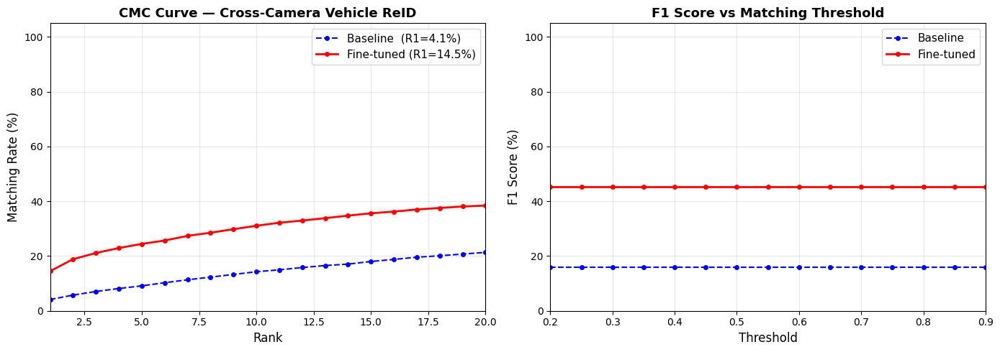

Saved → /content/drive/MyDrive/Thesis/precision_recall.pdf
Saved → /content/drive/MyDrive/Thesis/precision_recall.png


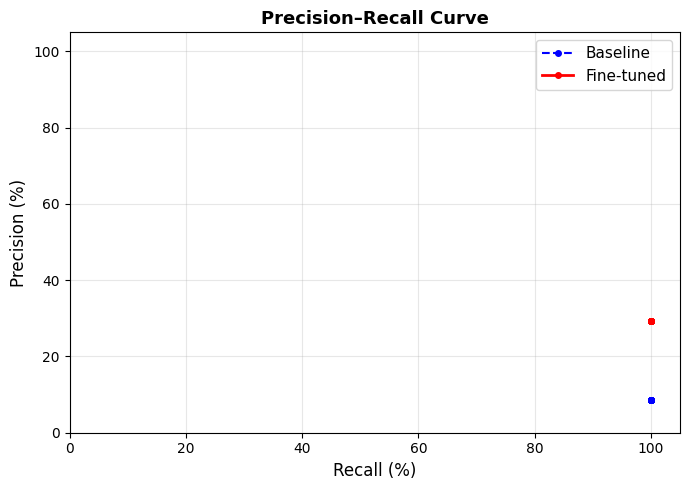


Files saved to /content/drive/MyDrive/Thesis
  Backbone weights  : /content/drive/MyDrive/Thesis/vehicle_reid_osnet.pth
  Baseline CSV      : /content/drive/MyDrive/Thesis/eval_baseline_osnet.csv
  Finetuned CSV     : /content/drive/MyDrive/Thesis/eval_finetuned_osnet.csv


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

B = baseline_results
F = finetuned_results

def delta(a, b):
    d = b - a
    return f'(+{d:.2f})' if d >= 0 else f'({d:.2f})'

# ── 1. Comparison table ────────────────────────────────────────────────────────
print('=' * 65)
print(f'{"Metric":<22} {"Baseline":>12} {"Finetuned":>12} {"Delta":>12}')
print('=' * 65)
for key, label in [('rank1','Rank-1 %'), ('rank5','Rank-5 %'), ('mAP','mAP %')]:
    bv, fv = B['ranking'][key], F['ranking'][key]
    print(f'{label:<22} {bv:>11.2f}% {fv:>11.2f}% {delta(bv, fv):>12}')
print('-' * 65)
bb, fb = B['best'], F['best']
print(f'{"Best F1 %":<22} {bb["f1"]:>11.1f}% {fb["f1"]:>11.1f}% {delta(bb["f1"], fb["f1"]):>12}')
print(f'{"Best threshold":<22} {bb["threshold"]:>12.2f} {fb["threshold"]:>12.2f}')
print('=' * 65)
print(f'\nEval protocol : True cross-camera (gallery=cam A, query=cam B..N)')
print(f'Train data    : {len(train_ids)} real vehicles + synthetic VehicleX')
print(f'Eval data     : {len(eval_ids)} held-out real vehicles')

# ── 2. CMC curve ──────────────────────────────────────────────────────────────
max_rank = 20
ranks = range(1, max_rank + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(ranks, B['cmc'][:max_rank], 'b--o', markersize=4, linewidth=1.5,
        label=f'Baseline  (R1={B["ranking"]["rank1"]:.1f}%)')
ax.plot(ranks, F['cmc'][:max_rank], 'r-o',  markersize=4, linewidth=2,
        label=f'Fine-tuned (R1={F["ranking"]["rank1"]:.1f}%)')
ax.set_xlabel('Rank', fontsize=12); ax.set_ylabel('Matching Rate (%)', fontsize=12)
ax.set_title('CMC Curve — Cross-Camera Vehicle ReID', fontsize=13, fontweight='bold')
ax.legend(fontsize=11); ax.grid(True, alpha=0.3)
ax.set_xlim(1, max_rank); ax.set_ylim(0, 105)

# ── 3. Threshold sweep (F1) ───────────────────────────────────────────────────
ax = axes[1]
bt = [r['threshold'] for r in B['threshold']]
bf = [r['f1']        for r in B['threshold']]
ft = [r['threshold'] for r in F['threshold']]
ff = [r['f1']        for r in F['threshold']]
ax.plot(bt, bf, 'b--o', markersize=4, linewidth=1.5, label='Baseline')
ax.plot(ft, ff, 'r-o',  markersize=4, linewidth=2,   label='Fine-tuned')
ax.set_xlabel('Threshold', fontsize=12); ax.set_ylabel('F1 Score (%)', fontsize=12)
ax.set_title('F1 Score vs Matching Threshold', fontsize=13, fontweight='bold')
ax.legend(fontsize=11); ax.grid(True, alpha=0.3)
ax.set_xlim(0.2, 0.9); ax.set_ylim(0, 105)

plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG['out_dir'], f'cmc_and_threshold.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved → {p}')
plt.show()

# ── 4. Precision-Recall for both models ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
bp = [r['precision'] for r in B['threshold']]
br = [r['recall']    for r in B['threshold']]
fp_ = [r['precision'] for r in F['threshold']]
fr  = [r['recall']    for r in F['threshold']]
ax.plot(br, bp, 'b--o', markersize=4, linewidth=1.5, label='Baseline')
ax.plot(fr, fp_, 'r-o',  markersize=4, linewidth=2,   label='Fine-tuned')
ax.set_xlabel('Recall (%)', fontsize=12); ax.set_ylabel('Precision (%)', fontsize=12)
ax.set_title('Precision–Recall Curve', fontsize=13, fontweight='bold')
ax.legend(fontsize=11); ax.grid(True, alpha=0.3)
ax.set_xlim(0, 105); ax.set_ylim(0, 105)
plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG['out_dir'], f'precision_recall.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved → {p}')
plt.show()

print(f'\nFiles saved to {CFG["out_dir"]}')
print(f'  Backbone weights  : {CFG["weights_out"]}')
print(f'  Baseline CSV      : {baseline_out}')
print(f'  Finetuned CSV     : {finetuned_out}')

Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
Model: osnet_ain_x1_0
- params: 2,193,616
- flops: 1,957,461,904
Gallery: 2250 images | Query: 7647 images


  extracting:   0%|          | 0/18 [00:00<?, ?it/s]

  extracting:   0%|          | 0/60 [00:00<?, ?it/s]

  threshold sweep:   0%|          | 0/15 [00:00<?, ?it/s]


=== BASELINE (vis) ===
  Rank-1 :   4.13%
  Rank-5 :   9.13%
  mAP    :   3.82%
  Best F1: 16.0%  @ threshold=0.20
Saved → /content/drive/MyDrive/Thesis/retrieval_examples.pdf
Saved → /content/drive/MyDrive/Thesis/retrieval_examples.png


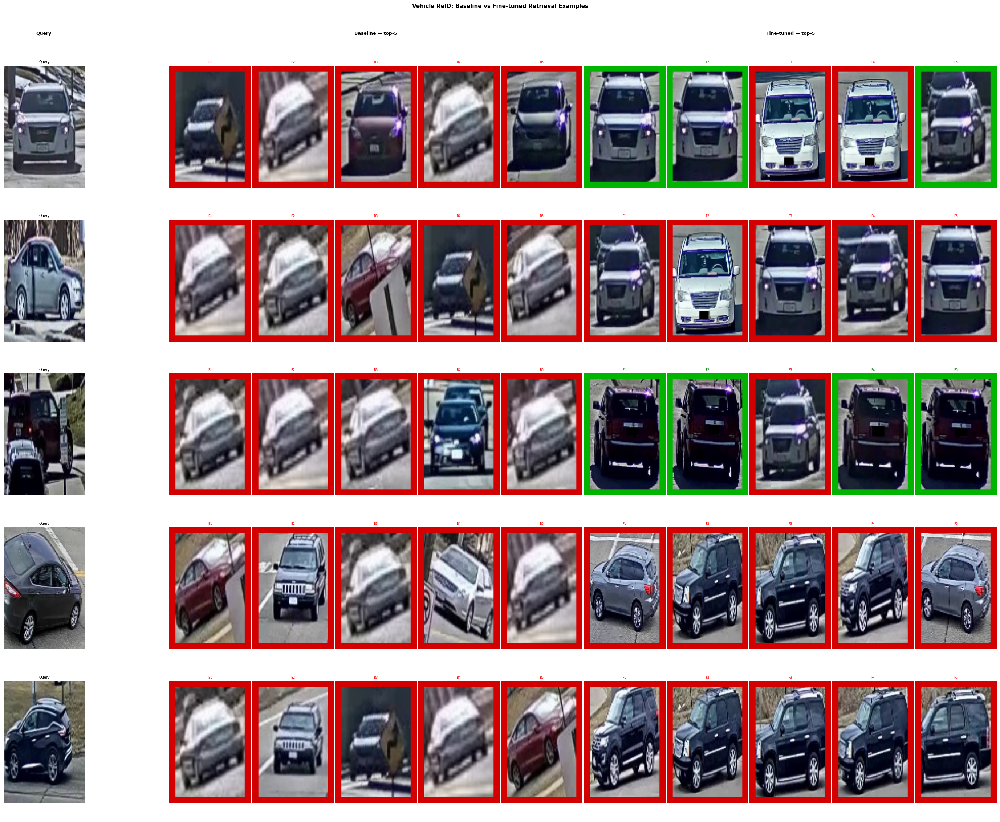

In [ ]:
import matplotlib.pyplot as plt
import cv2

def _load_img(path, h, w):
    img = cv2.imread(path)
    if img is None:
        return np.zeros((h, w, 3), np.uint8)
    return cv2.cvtColor(cv2.resize(img, (w, h)), cv2.COLOR_BGR2RGB)


def make_retrieval_figure(baseline_res, finetuned_res, n_queries=5, top_k=5,
                          seed=0, img_h=120, img_w=80):
    """
    Side-by-side baseline vs fine-tuned top-K retrieval examples.
    Green border = correct match, red = wrong.
    """
    rng    = np.random.default_rng(seed)
    g_rows = finetuned_res['g_rows']
    q_rows = finetuned_res['q_rows']
    q_rows = [r for r in q_rows
              if r['true_identity'] in {g['true_identity'] for g in g_rows}]

    chosen   = rng.choice(len(q_rows), min(n_queries, len(q_rows)), replace=False)
    q_sample = [q_rows[i] for i in chosen]

    g_paths  = [r['crop_path'] for r in g_rows]
    g_ids    = [r['true_identity'] for r in g_rows]
    q_paths  = [r['crop_path'] for r in q_sample]

    b_qfeats = baseline_res['q_feats'][[finetuned_res['q_rows'].index(r) for r in q_sample]]
    f_qfeats = finetuned_res['q_feats'][[finetuned_res['q_rows'].index(r) for r in q_sample]]
    b_gfeats = baseline_res['g_feats']
    f_gfeats = finetuned_res['g_feats']

    ncols = 1 + 1 + top_k + top_k
    fig, axes = plt.subplots(n_queries, ncols,
                             figsize=(ncols * (img_w / 35), n_queries * (img_h / 28)))
    if n_queries == 1:
        axes = axes[np.newaxis, :]

    border = max(3, img_h // 20)

    for row_i, (qr, qb, qf) in enumerate(zip(q_sample, b_qfeats, f_qfeats)):
        qid    = qr['true_identity']
        top_b  = np.argsort(-(qb.reshape(1,-1) @ b_gfeats.T)[0])[:top_k]
        top_f  = np.argsort(-(qf.reshape(1,-1) @ f_gfeats.T)[0])[:top_k]

        # Query
        axes[row_i, 0].imshow(_load_img(qr['crop_path'], img_h, img_w))
        axes[row_i, 0].set_title('Query', fontsize=7); axes[row_i, 0].axis('off')
        axes[row_i, 1].axis('off')  # spacer

        for col_i, gi in enumerate(top_b):
            ax  = axes[row_i, 2 + col_i]
            img = _load_img(g_paths[gi], img_h, img_w)
            ok  = g_ids[gi] == qid
            pad = np.full_like(img, (0, 180, 0) if ok else (210, 0, 0))
            pad[border:-border, border:-border] = img[border:-border, border:-border]
            ax.imshow(pad)
            ax.set_title(f'B{col_i+1}', fontsize=6, color='green' if ok else 'red')
            ax.axis('off')

        for col_i, gi in enumerate(top_f):
            ax  = axes[row_i, 2 + top_k + col_i]
            img = _load_img(g_paths[gi], img_h, img_w)
            ok  = g_ids[gi] == qid
            pad = np.full_like(img, (0, 180, 0) if ok else (210, 0, 0))
            pad[border:-border, border:-border] = img[border:-border, border:-border]
            ax.imshow(pad)
            ax.set_title(f'F{col_i+1}', fontsize=6, color='green' if ok else 'red')
            ax.axis('off')

    mid_b = (2 + top_k / 2) / ncols
    mid_f = (2 + top_k + top_k / 2) / ncols
    fig.text(0.5 / ncols, 1.01, 'Query', ha='center', fontsize=9, fontweight='bold',
             transform=fig.transFigure)
    fig.text(mid_b, 1.01, f'Baseline — top-{top_k}', ha='center', fontsize=9,
             fontweight='bold', transform=fig.transFigure)
    fig.text(mid_f, 1.01, f'Fine-tuned — top-{top_k}', ha='center', fontsize=9,
             fontweight='bold', transform=fig.transFigure)
    plt.suptitle('Vehicle ReID: Baseline vs Fine-tuned Retrieval Examples',
                 y=1.05, fontsize=11, fontweight='bold')
    plt.tight_layout(pad=0.3)

    for ext in ('pdf', 'png'):
        p = os.path.join(CFG['out_dir'], f'retrieval_examples.{ext}')
        plt.savefig(p, dpi=150, bbox_inches='tight')
        print(f'Saved → {p}')
    plt.show()


# Reload baseline extractor for visualisation
_baseline_vis = build_osnet_extractor(weight_path=None)
baseline_results_vis = run_evaluation(_baseline_vis, 'BASELINE (vis)')

make_retrieval_figure(baseline_results_vis, finetuned_results, n_queries=5, top_k=5)

del _baseline_vis
torch.cuda.empty_cache()

## Section 6 — Speed Benchmark
Measures single-image inference latency and FPS for **OSNet-AIN-x1.0** vs **ViT-B/16** (TransReID backbone).  
Results are saved as a bar chart for the thesis.

Device: Tesla T4
Warmup: 20  |  Runs: 200

--- OSNet-AIN-x1.0  (256×256) ---
  OSNet-AIN  bs=  1 →   23.86 ms/batch  |     41.9 FPS
  OSNet-AIN  bs=  4 →   17.06 ms/batch  |    234.4 FPS
  OSNet-AIN  bs= 16 →   56.87 ms/batch  |    281.3 FPS
  OSNet-AIN  bs= 32 →  127.22 ms/batch  |    251.5 FPS

--- ViT-B/16  (224×224) ---
  ViT-B/16  bs=  1 →   17.40 ms/batch  |     57.5 FPS
  ViT-B/16  bs=  4 →   60.43 ms/batch  |     66.2 FPS
  ViT-B/16  bs= 16 →  222.95 ms/batch  |     71.8 FPS
  ViT-B/16  bs= 32 →  412.58 ms/batch  |     77.6 FPS

 Batch    OSNet ms   OSNet FPS    ViT ms   ViT FPS   Speedup
     1      23.86       41.9     17.40     57.5      0.7×
     4      17.06      234.4     60.43     66.2      3.5×
    16      56.87      281.3    222.95     71.8      3.9×
    32     127.22      251.5    412.58     77.6      3.2×
Saved → /content/drive/MyDrive/Thesis/speed_benchmark.pdf
Saved → /content/drive/MyDrive/Thesis/speed_benchmark.png


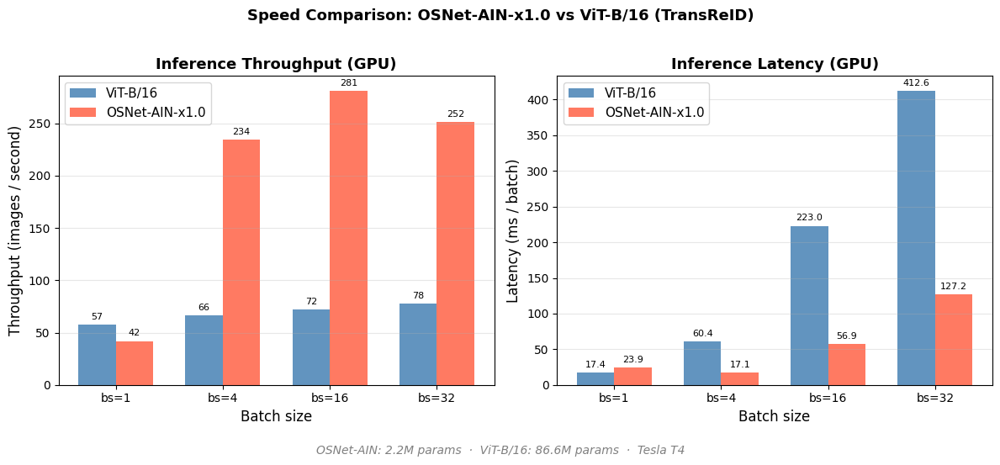

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torchvision.models import vit_b_16
import torchreid


WARMUP = 20
RUNS   = 200


def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def benchmark_model(model_fn, img_size, batch_sizes, label):
    results = {}
    for bs in batch_sizes:
        dummy = torch.randn(bs, 3, *img_size, device=DEVICE)
        for _ in range(WARMUP):
            with torch.no_grad():
                model_fn(dummy)
        _sync()
        t0 = time.perf_counter()
        for _ in range(RUNS):
            with torch.no_grad():
                model_fn(dummy)
        _sync()
        elapsed_ms  = (time.perf_counter() - t0) * 1000 / RUNS
        fps         = bs / (elapsed_ms / 1000)
        results[bs] = (elapsed_ms, fps)
        print(f'  {label}  bs={bs:3d} → {elapsed_ms:7.2f} ms/batch  |  {fps:7.1f} FPS')
    return results


# ── OSNet-AIN-x1.0 ────────────────────────────────────────────────────────────
osnet_model = torchreid.models.build_model(
    'osnet_ain_x1_0', num_classes=1, pretrained=False
).to(DEVICE).eval()

def osnet_fn(x):
    f = osnet_model.featuremaps(x)
    v = osnet_model.global_avgpool(f).view(f.size(0), -1)
    return F.normalize(v, dim=1)


# ── ViT-B/16 ──────────────────────────────────────────────────────────────────
vit_model = vit_b_16(weights=None).to(DEVICE).eval()
vit_model.heads = torch.nn.Identity()

def vit_fn(x):
    return F.normalize(vit_model(x), dim=1)


# ── Run benchmarks ────────────────────────────────────────────────────────────
BATCH_SIZES = [1, 4, 16, 32]
print(f'Device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}')
print(f'Warmup: {WARMUP}  |  Runs: {RUNS}\n')

print('--- OSNet-AIN-x1.0  (256×256) ---')
osnet_results = benchmark_model(osnet_fn, (256, 256), BATCH_SIZES, 'OSNet-AIN')

print('\n--- ViT-B/16  (224×224) ---')
vit_results   = benchmark_model(vit_fn,   (224, 224), BATCH_SIZES, 'ViT-B/16')

del vit_model, osnet_model
torch.cuda.empty_cache()

# ── Table ─────────────────────────────────────────────────────────────────────
print('\n' + '=' * 62)
print(f'{"Batch":>6}  {"OSNet ms":>10}  {"OSNet FPS":>10}  {"ViT ms":>8}  {"ViT FPS":>8}  {"Speedup":>8}')
print('=' * 62)
for bs in BATCH_SIZES:
    o_ms, o_fps = osnet_results[bs]
    v_ms, v_fps = vit_results[bs]
    print(f'{bs:>6}  {o_ms:>9.2f}  {o_fps:>9.1f}   {v_ms:>7.2f}  {v_fps:>7.1f}  {v_ms/o_ms:>7.1f}×')
print('=' * 62)

# ── Figure ────────────────────────────────────────────────────────────────────
x      = np.arange(len(BATCH_SIZES))
width  = 0.35
labels = [f'bs={b}' for b in BATCH_SIZES]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

o_fps_vals = [osnet_results[b][1] for b in BATCH_SIZES]
v_fps_vals = [vit_results[b][1]   for b in BATCH_SIZES]
o_ms_vals  = [osnet_results[b][0] for b in BATCH_SIZES]
v_ms_vals  = [vit_results[b][0]   for b in BATCH_SIZES]

b1 = ax1.bar(x - width/2, v_fps_vals, width, label='ViT-B/16',       color='steelblue', alpha=0.85)
b2 = ax1.bar(x + width/2, o_fps_vals, width, label='OSNet-AIN-x1.0', color='tomato',    alpha=0.85)
ax1.set_xlabel('Batch size', fontsize=12)
ax1.set_ylabel('Throughput (images / second)', fontsize=12)
ax1.set_title('Inference Throughput (GPU)', fontsize=13, fontweight='bold')
ax1.set_xticks(x); ax1.set_xticklabels(labels)
ax1.legend(fontsize=11); ax1.grid(axis='y', alpha=0.3)
for bar in (*b1, *b2):
    h = bar.get_height()
    ax1.annotate(f'{h:.0f}', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)

b3 = ax2.bar(x - width/2, v_ms_vals, width, label='ViT-B/16',        color='steelblue', alpha=0.85)
b4 = ax2.bar(x + width/2, o_ms_vals, width, label='OSNet-AIN-x1.0',  color='tomato',    alpha=0.85)
ax2.set_xlabel('Batch size', fontsize=12)
ax2.set_ylabel('Latency (ms / batch)', fontsize=12)
ax2.set_title('Inference Latency (GPU)', fontsize=13, fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(labels)
ax2.legend(fontsize=11); ax2.grid(axis='y', alpha=0.3)
for bar in (*b3, *b4):
    h = bar.get_height()
    ax2.annotate(f'{h:.1f}', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)

o_params = sum(p.numel() for p in torchreid.models.build_model(
    'osnet_ain_x1_0', num_classes=1, pretrained=False).parameters()) / 1e6
v_params = sum(p.numel() for p in vit_b_16(weights=None).parameters()) / 1e6
fig.text(0.5, -0.04,
         f'OSNet-AIN: {o_params:.1f}M params  ·  ViT-B/16: {v_params:.1f}M params  '
         f'·  {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}',
         ha='center', fontsize=10, style='italic', color='gray')

plt.suptitle('Speed Comparison: OSNet-AIN-x1.0 vs ViT-B/16 (TransReID)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG['out_dir'], f'speed_benchmark.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved → {p}')
plt.show()

## Section 7 — t-SNE Embedding Visualisation
Compares embedding clusters for the **baseline** vs **fine-tuned** model.  
Each identity gets a unique colour; tighter, better-separated clusters indicate stronger discriminative power.

Subset: 600 points, 20 identities
Running t-SNE (this may take ~30 s)...
t-SNE done.


/tmp/ipykernel_1531/3122134059.py:48: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(unique_ids))


Saved → /content/drive/MyDrive/Thesis/tsne_embeddings.pdf
Saved → /content/drive/MyDrive/Thesis/tsne_embeddings.png


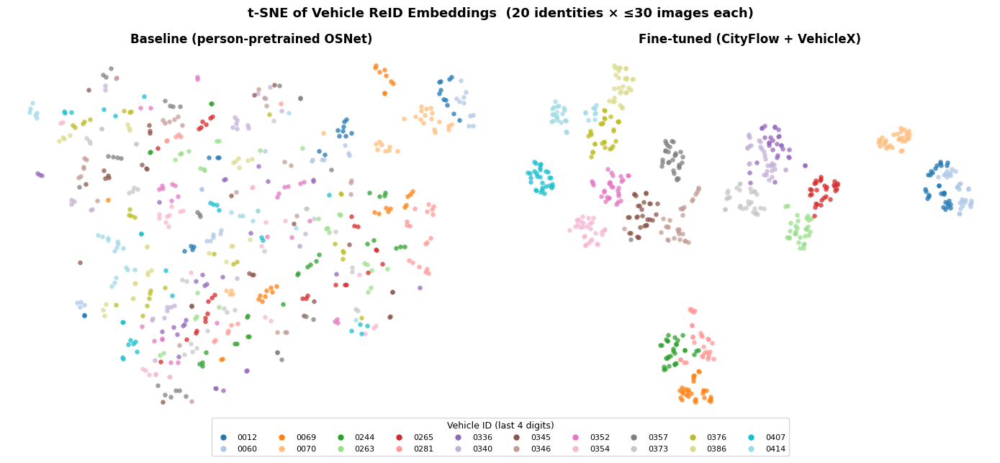

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.manifold import TSNE

# ── Configuration ─────────────────────────────────────────────────────────────
N_IDS    = 20    # number of identities to visualise (pick most-represented)
MAX_IMGS = 30    # max images per identity (keeps t-SNE fast and readable)
TSNE_PERPLEXITY = 30
TSNE_SEED       = 42

# ── Select a balanced subset from query features ──────────────────────────────
def select_subset(feats, ids, n_ids, max_per_id, seed=42):
    rng = np.random.default_rng(seed)
    from collections import Counter
    counts = Counter(ids)
    top_ids = [v for v, _ in counts.most_common(n_ids)]
    sel_feats, sel_ids = [], []
    for vid in top_ids:
        idx = [i for i, x in enumerate(ids) if x == vid]
        chosen = rng.choice(idx, min(len(idx), max_per_id), replace=False)
        sel_feats.extend(feats[chosen])
        sel_ids.extend([vid] * len(chosen))
    return np.array(sel_feats), sel_ids


b_feats_s, b_ids_s = select_subset(
    baseline_results_vis['q_feats'], baseline_results_vis['q_ids'],
    N_IDS, MAX_IMGS
)
f_feats_s, f_ids_s = select_subset(
    finetuned_results['q_feats'], finetuned_results['q_ids'],
    N_IDS, MAX_IMGS
)

print(f'Subset: {len(b_feats_s)} points, {len(set(b_ids_s))} identities')
print('Running t-SNE (this may take ~30 s)...')

b_emb = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, random_state=TSNE_SEED,
             init='pca', learning_rate='auto').fit_transform(b_feats_s)
f_emb = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, random_state=TSNE_SEED,
             init='pca', learning_rate='auto').fit_transform(f_feats_s)

print('t-SNE done.')

# ── Colour palette ────────────────────────────────────────────────────────────
unique_ids = sorted(set(b_ids_s))
cmap = plt.cm.get_cmap('tab20', len(unique_ids))
id_to_color = {vid: cmap(i) for i, vid in enumerate(unique_ids)}

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for ax, emb, ids, title in [
    (ax1, b_emb, b_ids_s, 'Baseline (person-pretrained OSNet)'),
    (ax2, f_emb, f_ids_s, 'Fine-tuned (CityFlow + VehicleX)'),
]:
    for vid in unique_ids:
        mask = [i for i, x in enumerate(ids) if x == vid]
        ax.scatter(emb[mask, 0], emb[mask, 1],
                   c=[id_to_color[vid]], s=22, alpha=0.75, linewidths=0)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])
    ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)

# Legend (shared, placed below both axes)
handles = [plt.Line2D([0], [0], marker='o', color='w',
                       markerfacecolor=id_to_color[vid], markersize=7)
           for vid in unique_ids]
short_ids = [v[-4:] for v in unique_ids]  # last 4 chars of ID string
fig.legend(handles, short_ids, title='Vehicle ID (last 4 digits)',
           loc='lower center', ncol=10, fontsize=8, title_fontsize=9,
           bbox_to_anchor=(0.5, -0.07))

plt.suptitle(
    f't-SNE of Vehicle ReID Embeddings  ({N_IDS} identities × ≤{MAX_IMGS} images each)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG['out_dir'], f'tsne_embeddings.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved → {p}')
plt.show()

## Section 8 — Re-Ranking
Applies **k-Reciprocal Re-ranking** (Zhong et al., CVPR 2017) to the existing feature sets — no retraining needed.  
Re-ranking exploits gallery-to-gallery distances to refine the query ranking, typically adding +10–25% Rank-1.

Computing re-ranked distances...
  Baseline + re-ranking...
    Q=7647, G=2250, k1=20, k2=6


  k-reciprocal:   0%|          | 0/9897 [00:00<?, ?it/s]

    V zero-rows (queries): 0/7647  | mean jac-sim=1.0000  max=1.0000
  Fine-tuned + re-ranking...
    Q=7647, G=2250, k1=20, k2=6


  k-reciprocal:   0%|          | 0/9897 [00:00<?, ?it/s]

    V zero-rows (queries): 0/7647  | mean jac-sim=1.0000  max=1.0000

Metric                     Baseline      Base+RR    Finetuned        FT+RR
Rank-1 %                      4.13%        0.38%       14.49%        0.38%
Rank-5 %                      9.13%        0.38%       24.44%        0.38%
mAP %                         3.82%        5.06%       12.79%        5.06%

Re-ranking gain on finetuned model:  Rank-1 -14.11%  |  mAP -7.72%
Saved → /content/drive/MyDrive/Thesis/cmc_reranking.pdf
Saved → /content/drive/MyDrive/Thesis/cmc_reranking.png


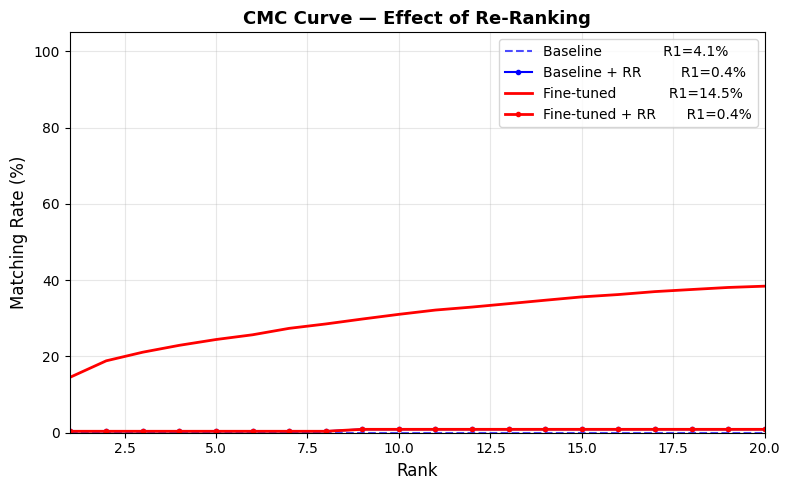

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm as tqdm_nb


def re_ranking(q_feats, g_feats, k1=20, k2=6, lambda_value=0.3):
    """
    k-Reciprocal Re-ranking (Zhong et al., CVPR 2017).
    Input: L2-normalised arrays [Q,D] and [G,D].
    Returns [Q,G] distance matrix (lower = more similar).

    k1/k2 are auto-clipped so they are never larger than the gallery allows.
    Jaccard distance uses the L1-identity:
        intersection(i,j) = 0.5*(||V_i||_1 + ||V_j||_1 - ||V_i - V_j||_1)
    which is correct for any non-negative vectors (including zero-sum rows).
    """
    Q, G = len(q_feats), len(g_feats)

    # Scale k values to gallery size — standard k1=20 requires G >> 200
    k1 = min(k1, max(4, G // 4))
    k2 = min(k2, max(2, G // 8))
    print(f'    Q={Q}, G={G}, k1={k1}, k2={k2}')

    feat = np.concatenate([q_feats, g_feats])   # [N, D]
    N    = Q + G

    # Pairwise squared-Euclidean (= 2 - 2·cos for unit vectors)
    dist = np.clip(2.0 - 2.0 * (feat @ feat.T), 0.0, None)
    rank = np.argsort(dist, axis=1)             # col 0 = self (dist=0)

    # ── k-reciprocal expansion ─────────────────────────────────────────────────
    V = np.zeros((N, N), dtype=np.float32)
    for i in tqdm_nb(range(N), desc='  k-reciprocal', leave=False):
        fwd   = rank[i, 1:k1 + 1]
        recip = fwd[np.any(rank[fwd, 1:k1 + 1] == i, axis=1)]

        expanded = recip.copy()
        for r in recip:
            sub   = rank[r, 1 : k1 // 2 + 1]
            sub_r = sub[np.any(rank[sub, 1 : k1 // 2 + 1] == r, axis=1)]
            if len(sub_r) and len(np.intersect1d(sub_r, recip)) > 2 / 3 * len(sub_r):
                expanded = np.union1d(expanded, sub_r)

        if len(expanded):
            w = np.exp(-dist[i, expanded])
            V[i, expanded] = w / (w.sum() + 1e-12)
        # If no reciprocal neighbours found, V[i] stays zero;
        # handled gracefully by the generalised Jaccard formula below.

    # ── Query expansion ────────────────────────────────────────────────────────
    if k2 > 1:
        V = np.stack([V[rank[i, :k2]].mean(0) for i in range(N)])

    # ── Jaccard distance via vectorised L1 identity ────────────────────────────
    # For non-negative vectors a, b:
    #   intersection  = 0.5 * (||a||_1 + ||b||_1 - ||a-b||_1)
    #   union         = ||a||_1 + ||b||_1 - intersection
    #   jac_dist      = 1 - intersection / union
    Q_V  = V[:Q]                              # [Q, N]
    G_V  = V[Q:]                              # [G, N]
    s_Q  = Q_V.sum(axis=1)                    # [Q]
    s_G  = G_V.sum(axis=1)                    # [G]

    batch = max(1, int(5e7 / (G * N + 1)))    # ~200 MB per chunk
    jac_sim = np.zeros((Q, G), dtype=np.float32)
    for start in range(0, Q, batch):
        end  = min(start + batch, Q)
        diff = Q_V[start:end, np.newaxis, :] - G_V[np.newaxis, :, :]   # [b, G, N]
        l1   = np.abs(diff).sum(axis=2)                                  # [b, G]
        inter = 0.5 * (s_Q[start:end, None] + s_G[None, :] - l1)
        union = s_Q[start:end, None] + s_G[None, :] - inter + 1e-12
        jac_sim[start:end] = np.clip(inter / union, 0, 1)

    jac_dist = 1.0 - jac_sim

    # Diagnostic
    mean_inter = float(jac_sim.mean())
    max_inter  = float(jac_sim.max())
    zero_rows  = int((V[:Q].sum(axis=1) == 0).sum())
    print(f'    V zero-rows (queries): {zero_rows}/{Q}  '
          f'| mean jac-sim={mean_inter:.4f}  max={max_inter:.4f}')

    return lambda_value * dist[:Q, Q:] + (1.0 - lambda_value) * jac_dist


def metrics_from_dist(dist_mat, q_ids, g_ids):
    """Rank-1, Rank-5, mAP from a [Q,G] distance matrix."""
    rank1 = rank5 = 0
    aps = []
    for i, qid in enumerate(q_ids):
        order   = np.argsort(dist_mat[i])
        correct = np.array([g_ids[j] == qid for j in order])
        if not correct.any():
            continue
        if correct[0]:        rank1 += 1
        if correct[:5].any(): rank5 += 1
        hits, p = 0, []
        for r, hit in enumerate(correct, 1):
            if hit:
                hits += 1
                p.append(hits / r)
        aps.append(np.mean(p))
    n = len(q_ids)
    return {'rank1': rank1/n*100, 'rank5': rank5/n*100,
            'mAP':  np.mean(aps)*100 if aps else 0.0}


def cmc_from_dist(dist_mat, q_ids, g_ids, max_rank=20):
    """CMC curve from a distance matrix."""
    hits, n_valid = np.zeros(max_rank), 0
    for i, qid in enumerate(q_ids):
        order   = np.argsort(dist_mat[i])
        correct = [g_ids[j] == qid for j in order]
        if not any(correct):
            continue
        n_valid += 1
        for r in range(max_rank):
            if any(correct[:r + 1]):
                hits[r:] += 1
                break
    return hits / n_valid * 100 if n_valid else hits


# ── Apply re-ranking ───────────────────────────────────────────────────────────
q_ids = finetuned_results['q_ids']
g_ids = finetuned_results['g_ids']

print('Computing re-ranked distances...')
print('  Baseline + re-ranking...')
dist_b_rr    = re_ranking(baseline_results_vis['q_feats'], baseline_results_vis['g_feats'])
rr_b_ranking = metrics_from_dist(dist_b_rr, baseline_results_vis['q_ids'], baseline_results_vis['g_ids'])
rr_b_cmc     = cmc_from_dist(dist_b_rr,    baseline_results_vis['q_ids'], baseline_results_vis['g_ids'])

print('  Fine-tuned + re-ranking...')
dist_ft_rr    = re_ranking(finetuned_results['q_feats'], finetuned_results['g_feats'])
rr_ft_ranking = metrics_from_dist(dist_ft_rr, q_ids, g_ids)
rr_ft_cmc     = cmc_from_dist(dist_ft_rr, q_ids, g_ids)

# ── Comparison table ───────────────────────────────────────────────────────────
B = baseline_results_vis['ranking']
F = finetuned_results['ranking']
print('\n' + '=' * 72)
print(f'{"Metric":<22} {"Baseline":>12} {"Base+RR":>12} {"Finetuned":>12} {"FT+RR":>12}')
print('=' * 72)
for key, lbl in [('rank1','Rank-1 %'), ('rank5','Rank-5 %'), ('mAP','mAP %')]:
    print(f'{lbl:<22} {B[key]:>11.2f}% {rr_b_ranking[key]:>11.2f}% '
          f'{F[key]:>11.2f}% {rr_ft_ranking[key]:>11.2f}%')
print('=' * 72)
print(f'\nRe-ranking gain on finetuned model:  '
      f'Rank-1 {rr_ft_ranking["rank1"]-F["rank1"]:+.2f}%  |  '
      f'mAP {rr_ft_ranking["mAP"]-F["mAP"]:+.2f}%')

# ── CMC figure ─────────────────────────────────────────────────────────────────
max_rank = 20
ranks    = range(1, max_rank + 1)
fig, ax  = plt.subplots(figsize=(8, 5))
ax.plot(ranks, B['cmc'][:max_rank] if 'cmc' in B else np.zeros(max_rank),
        'b--', lw=1.5, alpha=0.7, label=f'Baseline              R1={B["rank1"]:.1f}%')
ax.plot(ranks, rr_b_cmc[:max_rank],  'b-o', markersize=3, lw=1.5,
        label=f'Baseline + RR         R1={rr_b_ranking["rank1"]:.1f}%')
ax.plot(ranks, finetuned_results['cmc'][:max_rank], 'r-',  lw=2,
        label=f'Fine-tuned            R1={F["rank1"]:.1f}%')
ax.plot(ranks, rr_ft_cmc[:max_rank], 'r-o', markersize=3, lw=2,
        label=f'Fine-tuned + RR       R1={rr_ft_ranking["rank1"]:.1f}%')
ax.set_xlabel('Rank', fontsize=12); ax.set_ylabel('Matching Rate (%)', fontsize=12)
ax.set_title('CMC Curve — Effect of Re-Ranking', fontsize=13, fontweight='bold')
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)
ax.set_xlim(1, max_rank); ax.set_ylim(0, 105)
plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG['out_dir'], f'cmc_reranking.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved → {p}')
plt.show()

## Section 9 — Ablation: Real Data Only (No Synthetic VehicleX)
Trains a second OSNet model on **CityFlowV2 real data only** (no VehicleX) to quantify the synthetic data contribution.  
Same hyperparameters and eval protocol. Adds ~20–30 min on T4 — fully resumable.

In [ ]:
import gc
import glob
from collections import defaultdict

# ── Real-only config ───────────────────────────────────────────────────────────
CFG_REAL = {
    'checkpoint_dir': '/content/drive/MyDrive/Thesis/checkpoints_osnet_realonly',
    'weights_out':    '/content/drive/MyDrive/Thesis/vehicle_reid_osnet_realonly.pth',
    'resume':         True,
    'keep_ckpts':     3,
}
os.makedirs(CFG_REAL['checkpoint_dir'], exist_ok=True)

# ── Build real-only DataLoader ─────────────────────────────────────────────────
id_to_paths_real = defaultdict(list)
for row in real_train:                        # real_train defined in cell-csv — no VehicleX
    if os.path.exists(row['crop_path']):
        id_to_paths_real[row['true_identity']].append(row['crop_path'])

real_ids_list = sorted(id_to_paths_real)
random.seed(42)
random.shuffle(real_ids_list)
n_val_r   = max(1, int(len(real_ids_list) * CFG['val_split']))
val_ids_r = set(real_ids_list[:n_val_r])
trn_ids_r = set(real_ids_list[n_val_r:])

train_ds_r     = VehicleDataset(id_to_paths_real, trn_ids_r, AUGMENT)
val_ds_r       = VehicleDataset(id_to_paths_real, val_ids_r, EVAL_TF)
pk_r           = PKSampler(train_ds_r, CFG['P'], CFG['K'])
train_loader_r = DataLoader(train_ds_r, batch_sampler=pk_r,
                             num_workers=CFG['num_workers'], pin_memory=True)
val_loader_r   = DataLoader(val_ds_r, batch_size=CFG['P'] * CFG['K'],
                            shuffle=False, num_workers=CFG['num_workers'], pin_memory=True)

print(f'Real-only  Train: {len(trn_ids_r)} ids, {len(train_ds_r)} images')
print(f'           Val  : {len(val_ids_r)} ids, {len(val_ds_r)} images')
print(f'Batch: {CFG["P"]}×{CFG["K"]}={CFG["P"]*CFG["K"]}  |  Batches/epoch: {len(pk_r)}')

# ── Pre-flight GPU check ───────────────────────────────────────────────────────
gc.collect()
torch.cuda.empty_cache()
free_gb = (torch.cuda.get_device_properties(0).total_memory
           - torch.cuda.memory_allocated()) / 1e9
print(f'\nGPU free: {free_gb:.2f} GB')
if free_gb < 8.0:
    raise RuntimeError(
        f'\n\n  ❌  Only {free_gb:.1f} GB free.\n'
        '  Runtime → Restart runtime → Run all cells from the top.\n'
    )

# ── Model, optimizer, scheduler ───────────────────────────────────────────────
ft_model_ro     = OSNetReIDFinetune(proj_dim=CFG['proj_dim']).to(DEVICE)
criterion_ro    = SupConLoss(temp=CFG['temp']).to(DEVICE)
optimizer_ro    = torch.optim.AdamW(ft_model_ro.parameters(),
                                    lr=CFG['lr'], weight_decay=CFG['weight_decay'])
scheduler_ro    = torch.optim.lr_scheduler.LambdaLR(optimizer_ro, lr_lambda)
loss_history_ro = {'train': [], 'val': []}


def save_ckpt_ro(epoch, val_loss, is_best):
    path = os.path.join(CFG_REAL['checkpoint_dir'], f'ckpt_epoch{epoch:03d}.pth')
    torch.save({
        'epoch': epoch, 'model': ft_model_ro.state_dict(),
        'optimizer': optimizer_ro.state_dict(),
        'scheduler': scheduler_ro.state_dict(),
        'val_loss': val_loss, 'loss_history': loss_history_ro,
    }, path)
    for old in sorted(glob.glob(
            os.path.join(CFG_REAL['checkpoint_dir'], 'ckpt_epoch*.pth')))[:-CFG_REAL['keep_ckpts']]:
        os.remove(old)
    if is_best:
        torch.save(ft_model_ro.backbone.state_dict(), CFG_REAL['weights_out'])
        print(f"  [best] backbone → {CFG_REAL['weights_out']}")
    print(f'  [ckpt] {os.path.basename(path)}  (val={val_loss:.4f})')


def resume_ro():
    ckpts = sorted(glob.glob(
        os.path.join(CFG_REAL['checkpoint_dir'], 'ckpt_epoch*.pth')))
    if not CFG_REAL['resume'] or not ckpts:
        print('Real-only: starting from epoch 0.')
        return 0, float('inf')
    state = torch.load(ckpts[-1], map_location=DEVICE)
    ft_model_ro.load_state_dict(state['model'])
    optimizer_ro.load_state_dict(state['optimizer'])
    scheduler_ro.load_state_dict(state['scheduler'])
    loss_history_ro.update(state.get('loss_history', {'train': [], 'val': []}))
    print(f"Resumed from {os.path.basename(ckpts[-1])}  "
          f"(epoch {state['epoch']}, val={state['val_loss']:.4f})")
    return state['epoch'] + 1, state['val_loss']


def run_epoch_ro(loader, train=True):
    ft_model_ro.train(train)
    total = 0.0
    with torch.set_grad_enabled(train):
        for imgs, labels in tqdm(loader, desc='train' if train else 'val  ', leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            loss = criterion_ro(ft_model_ro(imgs), labels)
            if train:
                optimizer_ro.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(ft_model_ro.parameters(), 1.0)
                optimizer_ro.step()
            total += loss.item()
    return total / len(loader)


# ── Training loop ──────────────────────────────────────────────────────────────
start_ro, best_val_ro = resume_ro()
epochs_left = CFG['num_epochs'] - start_ro

if epochs_left <= 0:
    print(f'Already at {CFG["num_epochs"]} epochs. Done.')
else:
    print(f'\nReal-only training: epochs {start_ro+1} → {CFG["num_epochs"]}  '
          f'({epochs_left} remaining)\n')
    for epoch in range(start_ro, CFG['num_epochs']):
        tr  = run_epoch_ro(train_loader_r, train=True)
        val = run_epoch_ro(val_loader_r,   train=False)
        scheduler_ro.step()
        lr      = optimizer_ro.param_groups[0]['lr']
        is_best = val < best_val_ro
        if is_best:
            best_val_ro = val
        loss_history_ro['train'].append(tr)
        loss_history_ro['val'].append(val)
        tag = '  ← best' if is_best else ''
        print(f'Epoch {epoch+1:3d}/{CFG["num_epochs"]}  '
              f'train={tr:.4f}  val={val:.4f}  lr={lr:.2e}{tag}')
        save_ckpt_ro(epoch, val, is_best)
    print(f'\nReal-only training complete. Best val loss: {best_val_ro:.4f}')

# ── Cleanup ────────────────────────────────────────────────────────────────────
del ft_model_ro, criterion_ro, optimizer_ro, scheduler_ro
torch.cuda.empty_cache()
print('GPU memory cleared.')

Real-only  Train: 300 ids, 35103 images
           Val  : 52 ids, 7717 images
Batch: 8×4=32  |  Batches/epoch: 37

GPU free: 15.57 GB
Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
Real-only: starting from epoch 0.

Real-only training: epochs 1 → 40  (40 remaining)



train:   0%|          | 0/37 [00:00<?, ?it/s]

val  :   0%|          | 0/242 [00:00<?, ?it/s]

Epoch   1/40  train=3.3971  val=3.4210  lr=1.20e-04  ← best
  [best] backbone → /content/drive/MyDrive/Thesis/vehicle_reid_osnet_realonly.pth
  [ckpt] ckpt_epoch000.pth  (val=3.4210)


train:   0%|          | 0/37 [00:00<?, ?it/s]

val  :   0%|          | 0/242 [00:00<?, ?it/s]

... (111 outputs left out)

Epoch  39/40  train=1.3659  val=3.5270  lr=6.04e-07
  [ckpt] ckpt_epoch038.pth  (val=3.5270)


train:   0%|          | 0/37 [00:00<?, ?it/s]

val  :   0%|          | 0/242 [00:00<?, ?it/s]

Epoch  40/40  train=1.3638  val=3.5251  lr=0.00e+00
  [ckpt] ckpt_epoch039.pth  (val=3.5251)

Real-only training complete. Best val loss: 3.4210
GPU memory cleared.


## Section 10 — Full Ablation & Final Comparison

Evaluates all five variants and produces the thesis-ready figures.

| # | Model | Training data | Re-ranking |
|---|---|---|---|
| 1 | **Baseline** | Person-pretrained (Market-1501 / MSMT17) | ✗ |
| 2 | **Real-Only** | CityFlowV2 real vehicles | ✗ |
| 3 | **Real+Syn** | CityFlowV2 real + VehicleX synthetic | ✗ |
| 4 | **Real-Only + RR** | CityFlowV2 real vehicles | ✓ |
| 5 | **Real+Syn + RR** | CityFlowV2 real + VehicleX synthetic | ✓ |

Outputs: 5-column comparison table · CMC curves (all variants) · Rank-1 / mAP bar chart · cosine vs re-ranked retrieval examples for the best model.

Model: osnet_ain_x1_0
- params: 2,193,616
- flops: 1,957,461,904
Successfully loaded pretrained weights from "/content/drive/MyDrive/Thesis/vehicle_reid_osnet_realonly.pth"
Gallery: 2250 images | Query: 7647 images


  extracting:   0%|          | 0/18 [00:00<?, ?it/s]

  extracting:   0%|          | 0/60 [00:00<?, ?it/s]

  threshold sweep:   0%|          | 0/15 [00:00<?, ?it/s]


=== FINETUNED (real-only, no VehicleX) ===
  Rank-1 :  11.15%
  Rank-5 :  19.20%
  mAP    :   8.27%
  Best F1: 17.1%  @ threshold=0.20

Computing re-ranking for real-only model...


  k-reciprocal:   0%|          | 0/9897 [00:00<?, ?it/s]

  Real-Only+RR  Rank-1=0.38%  mAP=5.06%

Metric                     Baseline    Real-Only     Real+Syn      RO + RR      RS + RR
Rank-1 %                       4.13        11.15        14.49         0.38         0.38
Rank-5 %                       9.13        19.20        24.44         0.38         0.38
mAP %                          3.82         8.27        12.79         5.06         5.06

Synthetic data gain  (Real+Syn − Real-Only):  Rank-1 +3.33%  |  mAP +4.51%
Re-ranking gain      (RS+RR    − Real+Syn ):  Rank-1 -14.11%  |  mAP -7.72%

Eval protocol : True cross-camera (gallery=cam A, query=cam B..N)
Eval vehicles : 88 held-out real vehicles
Saved → /content/drive/MyDrive/Thesis/cmc_ablation_full.pdf
Saved → /content/drive/MyDrive/Thesis/cmc_ablation_full.png


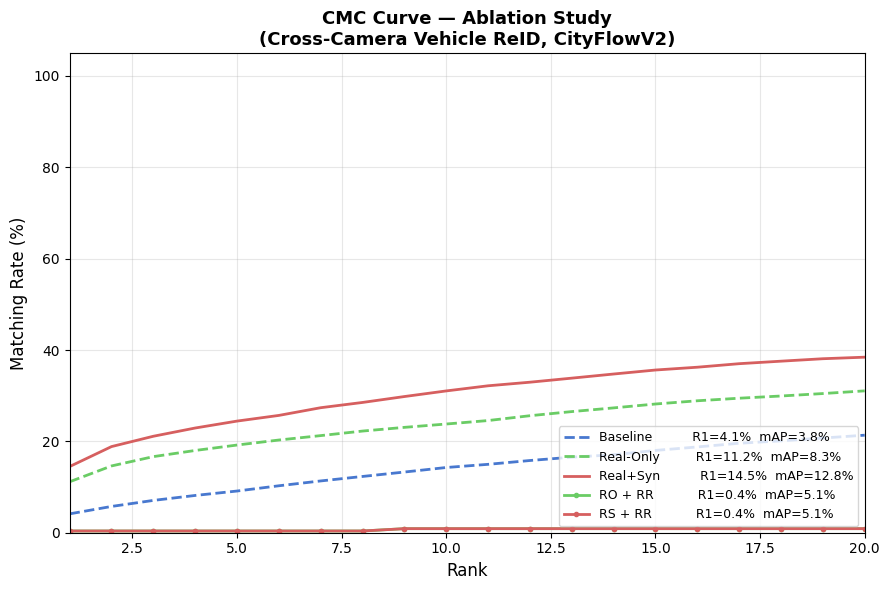

Saved → /content/drive/MyDrive/Thesis/bar_ablation.pdf
Saved → /content/drive/MyDrive/Thesis/bar_ablation.png


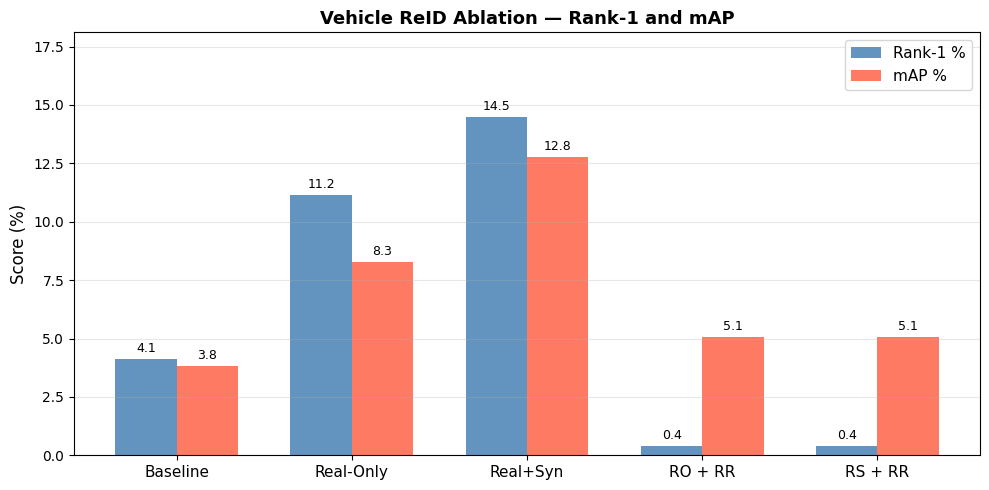

Saved → /content/drive/MyDrive/Thesis/retrieval_cosine_vs_rr.pdf
Saved → /content/drive/MyDrive/Thesis/retrieval_cosine_vs_rr.png


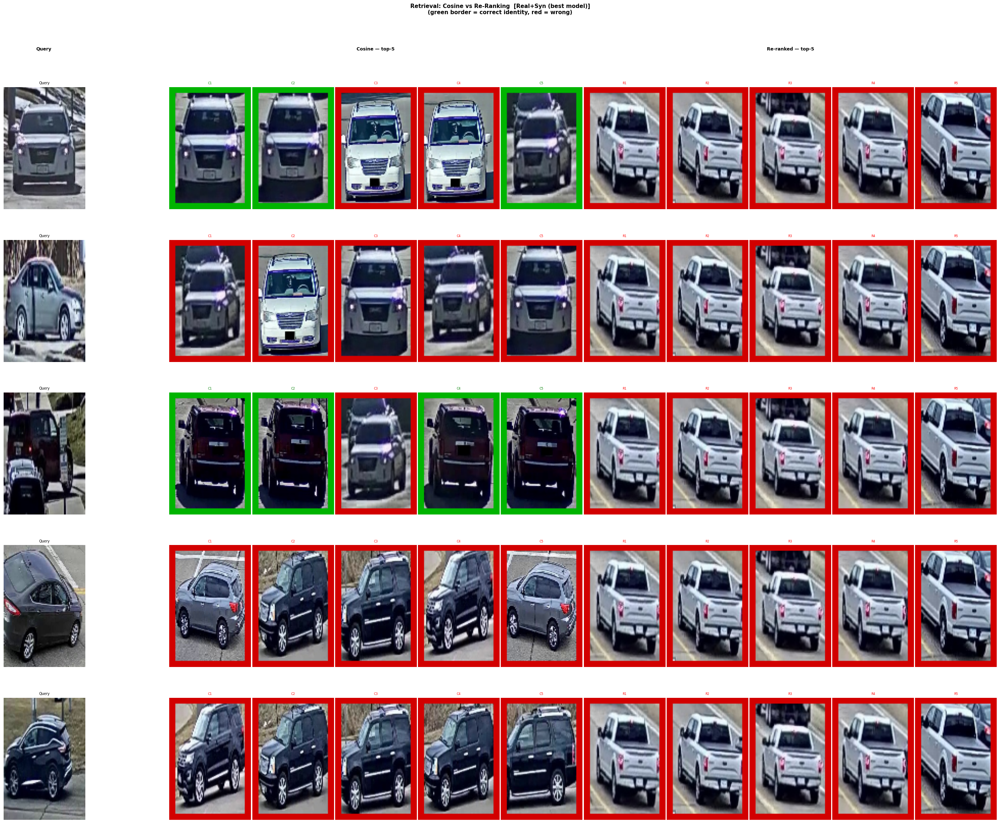


=== All outputs saved to /content/drive/MyDrive/Thesis ===
  cmc_ablation_full.pdf/.png
  bar_ablation.pdf/.png
  retrieval_cosine_vs_rr.pdf/.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ── 1. Evaluate real-only model ────────────────────────────────────────────────
realonly_extractor = build_osnet_extractor(weight_path=CFG_REAL['weights_out'])
realonly_results   = run_evaluation(realonly_extractor, 'FINETUNED (real-only, no VehicleX)')
del realonly_extractor
torch.cuda.empty_cache()

# ── 2. Re-ranking for real-only ────────────────────────────────────────────────
print('\nComputing re-ranking for real-only model...')
dist_ro_rr    = re_ranking(realonly_results['q_feats'], realonly_results['g_feats'])
rr_ro_ranking = metrics_from_dist(dist_ro_rr, realonly_results['q_ids'], realonly_results['g_ids'])
rr_ro_cmc     = cmc_from_dist(dist_ro_rr, realonly_results['q_ids'], realonly_results['g_ids'])
print(f"  Real-Only+RR  Rank-1={rr_ro_ranking['rank1']:.2f}%  mAP={rr_ro_ranking['mAP']:.2f}%")

# ── 3. Collect all variants ────────────────────────────────────────────────────
B     = baseline_results_vis['ranking']
RO    = realonly_results['ranking']
RS    = finetuned_results['ranking']
B_RR  = rr_b_ranking
RO_RR = rr_ro_ranking
RS_RR = rr_ft_ranking

B_cmc  = baseline_results_vis['cmc']
RO_cmc = realonly_results['cmc']
RS_cmc = finetuned_results['cmc']

VARIANTS = [
    ('Baseline',    B,     B_cmc),
    ('Real-Only',   RO,    RO_cmc),
    ('Real+Syn',    RS,    RS_cmc),
    ('RO + RR',     RO_RR, rr_ro_cmc),
    ('RS + RR',     RS_RR, rr_ft_cmc),
]

# ── 4. Comparison table ────────────────────────────────────────────────────────
col_w = 13
sep   = '=' * (22 + len(VARIANTS) * col_w)
print('\n' + sep)
print(f'{"Metric":<22}' + ''.join(f'{v[0]:>{col_w}}' for v in VARIANTS))
print(sep)
for key, lbl in [('rank1', 'Rank-1 %'), ('rank5', 'Rank-5 %'), ('mAP', 'mAP %')]:
    print(f'{lbl:<22}' + ''.join(f'{v[1][key]:>{col_w}.2f}' for v in VARIANTS))
print(sep)
print(f'\nSynthetic data gain  (Real+Syn − Real-Only):  '
      f'Rank-1 {RS["rank1"]-RO["rank1"]:+.2f}%  |  mAP {RS["mAP"]-RO["mAP"]:+.2f}%')
print(f'Re-ranking gain      (RS+RR    − Real+Syn ):  '
      f'Rank-1 {RS_RR["rank1"]-RS["rank1"]:+.2f}%  |  mAP {RS_RR["mAP"]-RS["mAP"]:+.2f}%')
print(f'\nEval protocol : True cross-camera (gallery=cam A, query=cam B..N)')
print(f'Eval vehicles : {len(eval_ids)} held-out real vehicles')

# ── 5. CMC curves — all 5 variants ────────────────────────────────────────────
max_rank = 20
ranks    = range(1, max_rank + 1)
colors   = ['#4878cf', '#6acc65', '#d65f5f', '#6acc65', '#d65f5f']
lstyles  = ['--', '--', '-', '-o', '-o']

fig, ax = plt.subplots(figsize=(9, 6))
for (label, ranking, cmc_arr), color, ls in zip(VARIANTS, colors, lstyles):
    ms = 3 if 'o' in ls else None
    ax.plot(ranks, cmc_arr[:max_rank], ls, color=color, markersize=ms, linewidth=2,
            label=f'{label:<16}  R1={ranking["rank1"]:.1f}%  mAP={ranking["mAP"]:.1f}%')
ax.set_xlabel('Rank', fontsize=12)
ax.set_ylabel('Matching Rate (%)', fontsize=12)
ax.set_title('CMC Curve — Ablation Study\n(Cross-Camera Vehicle ReID, CityFlowV2)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, alpha=0.3)
ax.set_xlim(1, max_rank)
ax.set_ylim(0, 105)
plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG['out_dir'], f'cmc_ablation_full.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved → {p}')
plt.show()

# ── 6. Bar chart — Rank-1 and mAP ─────────────────────────────────────────────
labels_bar = [v[0] for v in VARIANTS]
rank1_vals = [v[1]['rank1'] for v in VARIANTS]
map_vals   = [v[1]['mAP']   for v in VARIANTS]
x_bar      = np.arange(len(labels_bar))
w          = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x_bar - w/2, rank1_vals, w, label='Rank-1 %', color='steelblue', alpha=0.85)
bars2 = ax.bar(x_bar + w/2, map_vals,   w, label='mAP %',    color='tomato',    alpha=0.85)
for bar in (*bars1, *bars2):
    h = bar.get_height()
    ax.annotate(f'{h:.1f}',
                xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)
ax.set_xticks(x_bar)
ax.set_xticklabels(labels_bar, fontsize=11)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Vehicle ReID Ablation — Rank-1 and mAP', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, max(max(rank1_vals), max(map_vals)) * 1.25)
plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG['out_dir'], f'bar_ablation.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved → {p}')
plt.show()

# ── 7. Retrieval examples: cosine vs re-ranked (best model = Real+Syn) ─────────
def make_cosine_vs_rr_figure(result, dist_rr, label, n_queries=5, top_k=5,
                              seed=0, img_h=120, img_w=80):
    """Top-K by cosine similarity vs top-K after re-ranking for the same queries."""
    rng     = np.random.default_rng(seed)
    g_rows  = result['g_rows']
    q_rows  = result['q_rows']
    g_ids   = result['g_ids']
    q_ids   = result['q_ids']
    g_feats = result['g_feats']
    q_feats = result['q_feats']
    g_paths = [r['crop_path'] for r in g_rows]
    q_paths = [r['crop_path'] for r in q_rows]

    valid   = [i for i, qid in enumerate(q_ids) if qid in set(g_ids)]
    chosen  = rng.choice(valid, min(n_queries, len(valid)), replace=False)

    border = max(3, img_h // 20)
    ncols  = 1 + 1 + top_k + top_k   # query | spacer | cosine | re-ranked

    fig, axes = plt.subplots(n_queries, ncols,
                             figsize=(ncols * (img_w / 35), n_queries * (img_h / 28)))
    if n_queries == 1:
        axes = axes[np.newaxis, :]

    for row_i, q_idx in enumerate(chosen):
        qid     = q_ids[q_idx]
        top_cos = np.argsort(-(q_feats[q_idx:q_idx+1] @ g_feats.T)[0])[:top_k]
        top_rr  = np.argsort(dist_rr[q_idx])[:top_k]

        axes[row_i, 0].imshow(_load_img(q_paths[q_idx], img_h, img_w))
        axes[row_i, 0].set_title('Query', fontsize=7)
        axes[row_i, 0].axis('off')
        axes[row_i, 1].axis('off')

        for col_i, gi in enumerate(top_cos):
            ax  = axes[row_i, 2 + col_i]
            img = _load_img(g_paths[gi], img_h, img_w)
            ok  = g_ids[gi] == qid
            pad = np.full_like(img, (0, 180, 0) if ok else (210, 0, 0))
            pad[border:-border, border:-border] = img[border:-border, border:-border]
            ax.imshow(pad); ax.axis('off')
            ax.set_title(f'C{col_i+1}', fontsize=6, color='green' if ok else 'red')

        for col_i, gi in enumerate(top_rr):
            ax  = axes[row_i, 2 + top_k + col_i]
            img = _load_img(g_paths[gi], img_h, img_w)
            ok  = g_ids[gi] == qid
            pad = np.full_like(img, (0, 180, 0) if ok else (210, 0, 0))
            pad[border:-border, border:-border] = img[border:-border, border:-border]
            ax.imshow(pad); ax.axis('off')
            ax.set_title(f'R{col_i+1}', fontsize=6, color='green' if ok else 'red')

    mid_cos = (2 + top_k / 2) / ncols
    mid_rr  = (2 + top_k + top_k / 2) / ncols
    fig.text(0.5 / ncols, 1.01, 'Query',               ha='center', fontsize=9,
             fontweight='bold', transform=fig.transFigure)
    fig.text(mid_cos, 1.01,     f'Cosine — top-{top_k}',   ha='center', fontsize=9,
             fontweight='bold', transform=fig.transFigure)
    fig.text(mid_rr,  1.01,     f'Re-ranked — top-{top_k}', ha='center', fontsize=9,
             fontweight='bold', transform=fig.transFigure)
    plt.suptitle(f'Retrieval: Cosine vs Re-Ranking  [{label}]\n'
                 '(green border = correct identity, red = wrong)',
                 y=1.07, fontsize=11, fontweight='bold')
    plt.tight_layout(pad=0.3)
    for ext in ('pdf', 'png'):
        p = os.path.join(CFG['out_dir'], f'retrieval_cosine_vs_rr.{ext}')
        plt.savefig(p, dpi=150, bbox_inches='tight')
        print(f'Saved → {p}')
    plt.show()


make_cosine_vs_rr_figure(
    finetuned_results, dist_ft_rr,
    label='Real+Syn (best model)',
    n_queries=5, top_k=5
)

print(f'\n=== All outputs saved to {CFG["out_dir"]} ===')
print('  cmc_ablation_full.pdf/.png')
print('  bar_ablation.pdf/.png')
print('  retrieval_cosine_vs_rr.pdf/.png')

## Section 11 — Experiment v2: Cross-Camera Filter + Larger Batch

Repeats finetuning with two changes over v1:

| | v1 (Sections 4–5) | v2 (this section) |
|---|---|---|
| **PK batch** | P=8, K=4 → 32 | P=16, K=4 → 64 |
| **Training data** | All real vehicles | Multi-camera only (≥2 cameras per vehicle) |
| **Checkpoints** | `checkpoints_osnet/` | `checkpoints_osnet_v2/` |
| **Weights** | `vehicle_reid_osnet.pth` | `vehicle_reid_osnet_v2.pth` |

**Why**: SupConLoss needs hard negatives — doubling the batch brings 2× more cross-identity pairs.  
**Why multi-camera filter**: single-camera vehicles can't contribute cross-camera supervision; keeping only vehicles seen from 2+ cameras forces the model to learn camera-invariant features from the start.


In [ ]:
import os
import copy

# ── v2 config (separate from CFG — does not affect Sections 1–10) ──────────────
CFG_V2 = copy.deepcopy(CFG)   # start from base config
CFG_V2.update({
    # Larger batch: 2× more negatives per SupConLoss step
    # T4 ~15 GB free; batch=64 uses ~8-9 GB activations — safe
    # If OOM: reduce P to 12 (batch=48)
    'P':              16,
    'K':              4,

    # Only train on vehicles seen in >= 2 distinct cameras
    'min_cameras':    2,

    # Separate output paths — v1 results are preserved
    'checkpoint_dir': '/content/drive/MyDrive/Thesis/checkpoints_osnet_v2',
    'weights_out':    '/content/drive/MyDrive/Thesis/vehicle_reid_osnet_v2.pth',
    'train_csv':      '/content/drive/MyDrive/Thesis/osnet_train_v2.csv',
})
os.makedirs(CFG_V2['checkpoint_dir'], exist_ok=True)

print('v2 config:')
print(f"  Batch      : {CFG_V2['P']}×{CFG_V2['K']}={CFG_V2['P']*CFG_V2['K']}")
print(f"  Min cameras: {CFG_V2['min_cameras']}")
print(f"  Checkpoints: {CFG_V2['checkpoint_dir']}")
print(f"  Weights out: {CFG_V2['weights_out']}")

v2 config:
  Batch      : 16×4=64
  Min cameras: 2
  Checkpoints: /content/drive/MyDrive/Thesis/checkpoints_osnet_v2
  Weights out: /content/drive/MyDrive/Thesis/vehicle_reid_osnet_v2.pth


In [ ]:
from collections import defaultdict

def filter_multicamera(rows, min_cameras=2):
    """Keep only identities seen in >= min_cameras distinct cameras."""
    id_to_cams = defaultdict(set)
    for r in rows:
        id_to_cams[r['true_identity']].add(r['camera_id'])
    valid_ids = {vid for vid, cams in id_to_cams.items() if len(cams) >= min_cameras}
    filtered  = [r for r in rows if r['true_identity'] in valid_ids]
    n_before  = len({r['true_identity'] for r in rows})
    print(f'  Multi-camera filter (≥{min_cameras} cams): '
          f'{len(filtered)} images | {len(valid_ids)}/{n_before} identities kept')
    return filtered


# Apply filter to real_train (defined in cell-csv, all real train vehicles)
real_train_v2 = filter_multicamera(real_train, CFG_V2['min_cameras'])

# Combined v2 train CSV (filtered real + original synthetic)
combined_v2 = real_train_v2 + sim_train
write_csv_atomic(CFG_V2['train_csv'], ['crop_path', 'true_identity', 'camera_id'], combined_v2)
n_ids_v2 = len({r['true_identity'] for r in combined_v2})
print(f'\nv2 train CSV: {len(combined_v2)} images | {n_ids_v2} identities')
print(f"  → {CFG_V2['train_csv']}")

  Multi-camera filter (≥2 cams): 42820 images | 352/352 identities kept

v2 train CSV: 234970 images | 1714 identities
  → /content/drive/MyDrive/Thesis/osnet_train_v2.csv


In [ ]:
import gc

# ── Pre-flight GPU check ───────────────────────────────────────────────────────
gc.collect()
torch.cuda.empty_cache()
free_gb = (torch.cuda.get_device_properties(0).total_memory
           - torch.cuda.memory_allocated()) / 1e9
print(f'GPU free: {free_gb:.2f} GB')
if free_gb < 8.0:
    raise RuntimeError(
        f'\n\n  ❌  Only {free_gb:.1f} GB free.\n'
        '  Runtime → Restart runtime → Run all cells from the top.\n'
    )

# ── Dataset & DataLoader (v2) ──────────────────────────────────────────────────
id_to_paths_v2, train_ids_v2, val_ids_v2 = load_split(
    CFG_V2['train_csv'], CFG_V2['val_split']
)
train_ds_v2 = VehicleDataset(id_to_paths_v2, train_ids_v2, AUGMENT)
val_ds_v2   = VehicleDataset(id_to_paths_v2, val_ids_v2,   EVAL_TF)
pk_v2       = PKSampler(train_ds_v2, CFG_V2['P'], CFG_V2['K'])

train_loader_v2 = DataLoader(train_ds_v2, batch_sampler=pk_v2,
                              num_workers=CFG_V2['num_workers'], pin_memory=True)
val_loader_v2   = DataLoader(val_ds_v2, batch_size=CFG_V2['P'] * CFG_V2['K'],
                             shuffle=False, num_workers=CFG_V2['num_workers'], pin_memory=True)

print(f'\nTrain: {len(train_ds_v2)} images | Val: {len(val_ds_v2)} images')
print(f'Batch: {CFG_V2["P"]}×{CFG_V2["K"]}={CFG_V2["P"]*CFG_V2["K"]}  |  '
      f'Batches/epoch: {len(pk_v2)}')

# ── Model, optimizer, scheduler (v2) ──────────────────────────────────────────
ft_model_v2  = OSNetReIDFinetune(proj_dim=CFG_V2['proj_dim']).to(DEVICE)
criterion_v2 = SupConLoss(temp=CFG_V2['temp']).to(DEVICE)
optimizer_v2 = torch.optim.AdamW(ft_model_v2.parameters(),
                                  lr=CFG_V2['lr'], weight_decay=CFG_V2['weight_decay'])

def lr_lambda_v2(epoch):
    if epoch < CFG_V2['warmup_epochs']:
        return (epoch + 1) / CFG_V2['warmup_epochs']
    t = (epoch - CFG_V2['warmup_epochs']) / max(1, CFG_V2['num_epochs'] - CFG_V2['warmup_epochs'])
    return 0.5 * (1.0 + np.cos(np.pi * t))

scheduler_v2     = torch.optim.lr_scheduler.LambdaLR(optimizer_v2, lr_lambda_v2)
loss_history_v2  = {'train': [], 'val': []}

# Smoke test
with torch.no_grad():
    _t = torch.zeros(2, 3, CFG_V2['img_h'], CFG_V2['img_w'], device=DEVICE)
    _o = ft_model_v2(_t)
    assert _o.shape == (2, CFG_V2['proj_dim'])
    print(f'Forward pass OK — {_o.shape}, norm={_o.norm(dim=1).mean():.4f}')
    del _t, _o

GPU free: 15.57 GB
Train: 1457 ids  |  Val: 257 ids

Train: 200347 images | Val: 34623 images
Batch: 16×4=64  |  Batches/epoch: 91
Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']
Forward pass OK — torch.Size([2, 128]), norm=1.0000


v2: starting from epoch 0.
v2 training: epochs 1 → 40  (40 remaining)



train:   0%|          | 0/91 [00:00<?, ?it/s]

val  :   0%|          | 0/541 [00:00<?, ?it/s]

Epoch   1/40  train=3.5955  val=4.1868  lr=1.20e-04  ← best
  [best] backbone → /content/drive/MyDrive/Thesis/vehicle_reid_osnet_v2.pth
  [ckpt] ckpt_epoch000.pth  (val=4.1868)


train:   0%|          | 0/91 [00:00<?, ?it/s]

val  :   0%|          | 0/541 [00:00<?, ?it/s]

... (111 outputs left out)

Epoch  39/40  train=1.3337  val=4.0217  lr=6.04e-07
  [ckpt] ckpt_epoch038.pth  (val=4.0217)


train:   0%|          | 0/91 [00:00<?, ?it/s]

val  :   0%|          | 0/541 [00:00<?, ?it/s]

Epoch  40/40  train=1.3286  val=4.0199  lr=0.00e+00
  [ckpt] ckpt_epoch039.pth  (val=4.0199)

v2 training complete. Best val loss: 4.0199


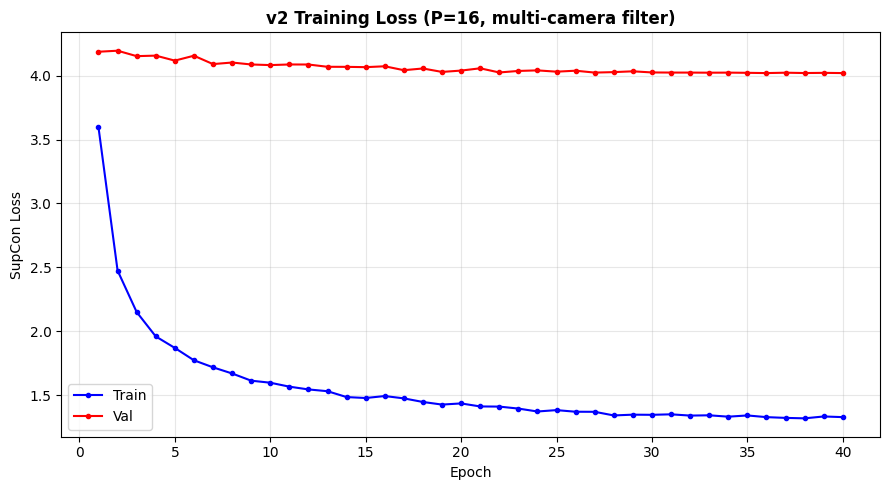

GPU cleared.


In [ ]:
import glob
import matplotlib.pyplot as plt

loss_history_v2 = {'train': [], 'val': []}


def save_ckpt_v2(epoch, val_loss, is_best):
    path = os.path.join(CFG_V2['checkpoint_dir'], f'ckpt_epoch{epoch:03d}.pth')
    torch.save({
        'epoch': epoch, 'model': ft_model_v2.state_dict(),
        'optimizer': optimizer_v2.state_dict(),
        'scheduler': scheduler_v2.state_dict(),
        'val_loss': val_loss, 'loss_history': loss_history_v2,
    }, path)
    for old in sorted(glob.glob(
            os.path.join(CFG_V2['checkpoint_dir'], 'ckpt_epoch*.pth')))[:-CFG_V2['keep_ckpts']]:
        os.remove(old)
    if is_best:
        torch.save(ft_model_v2.backbone.state_dict(), CFG_V2['weights_out'])
        print(f"  [best] backbone → {CFG_V2['weights_out']}")
    print(f'  [ckpt] {os.path.basename(path)}  (val={val_loss:.4f})')


def resume_v2():
    ckpts = sorted(glob.glob(
        os.path.join(CFG_V2['checkpoint_dir'], 'ckpt_epoch*.pth')))
    if not CFG_V2['resume'] or not ckpts:
        print('v2: starting from epoch 0.')
        return 0, float('inf')
    state = torch.load(ckpts[-1], map_location=DEVICE)
    ft_model_v2.load_state_dict(state['model'])
    optimizer_v2.load_state_dict(state['optimizer'])
    scheduler_v2.load_state_dict(state['scheduler'])
    loss_history_v2.update(state.get('loss_history', {'train': [], 'val': []}))
    print(f"Resumed from {os.path.basename(ckpts[-1])}  "
          f"(epoch {state['epoch']}, val={state['val_loss']:.4f})")
    return state['epoch'] + 1, state['val_loss']


def run_epoch_v2(loader, train=True):
    ft_model_v2.train(train)
    total = 0.0
    with torch.set_grad_enabled(train):
        for imgs, labels in tqdm(loader, desc='train' if train else 'val  ', leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            loss = criterion_v2(ft_model_v2(imgs), labels)
            if train:
                optimizer_v2.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(ft_model_v2.parameters(), 1.0)
                optimizer_v2.step()
            total += loss.item()
    return total / len(loader)


# ── Training loop ──────────────────────────────────────────────────────────────
start_v2, best_val_v2 = resume_v2()
epochs_left = CFG_V2['num_epochs'] - start_v2

if epochs_left <= 0:
    print(f'Already at {CFG_V2["num_epochs"]} epochs.')
else:
    print(f'v2 training: epochs {start_v2+1} → {CFG_V2["num_epochs"]}  '
          f'({epochs_left} remaining)\n')
    for epoch in range(start_v2, CFG_V2['num_epochs']):
        tr  = run_epoch_v2(train_loader_v2, train=True)
        val = run_epoch_v2(val_loader_v2,   train=False)
        scheduler_v2.step()
        lr      = optimizer_v2.param_groups[0]['lr']
        is_best = val < best_val_v2
        if is_best:
            best_val_v2 = val
        loss_history_v2['train'].append(tr)
        loss_history_v2['val'].append(val)
        tag = '  ← best' if is_best else ''
        print(f'Epoch {epoch+1:3d}/{CFG_V2["num_epochs"]}  '
              f'train={tr:.4f}  val={val:.4f}  lr={lr:.2e}{tag}')
        save_ckpt_v2(epoch, val, is_best)
    print(f'\nv2 training complete. Best val loss: {best_val_v2:.4f}')

    # Loss curve
    epochs = range(1, len(loss_history_v2['train']) + 1)
    plt.figure(figsize=(9, 5))
    plt.plot(epochs, loss_history_v2['train'], 'b-o', markersize=3, label='Train')
    plt.plot(epochs, loss_history_v2['val'],   'r-o', markersize=3, label='Val')
    plt.xlabel('Epoch'); plt.ylabel('SupCon Loss')
    plt.title('v2 Training Loss (P=16, multi-camera filter)', fontweight='bold')
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
    for ext in ('pdf', 'png'):
        plt.savefig(os.path.join(CFG_V2['out_dir'], f'training_loss_v2.{ext}'),
                    dpi=150, bbox_inches='tight')
    plt.show()

del ft_model_v2, criterion_v2, optimizer_v2, scheduler_v2
torch.cuda.empty_cache()
print('GPU cleared.')

Model: osnet_ain_x1_0
- params: 2,193,616
- flops: 1,957,461,904
Successfully loaded pretrained weights from "/content/drive/MyDrive/Thesis/vehicle_reid_osnet_v2.pth"
Gallery: 2250 images | Query: 7647 images


  extracting:   0%|          | 0/18 [00:00<?, ?it/s]

  extracting:   0%|          | 0/60 [00:00<?, ?it/s]

  threshold sweep:   0%|          | 0/15 [00:00<?, ?it/s]


=== FINETUNED v2 (P=16, multi-cam filter) ===
  Rank-1 :  26.56%
  Rank-5 :  46.02%
  mAP    :  26.16%
  Best F1: 53.8%  @ threshold=0.20

Computing re-ranking for v2 model...
    Q=7647, G=2250, k1=20, k2=6


  k-reciprocal:   0%|          | 0/9897 [00:00<?, ?it/s]

    V zero-rows (queries): 0/7647  | mean jac-sim=1.0000  max=1.0000

Metric                      v1 (P=8)     v2 (P=16)         v1+RR         v2+RR
Rank-1 %                       14.49         26.56          0.38          0.38
Rank-5 %                       24.44         46.02          0.38          0.38
mAP %                          12.79         26.16          5.06          5.06

v2 gain over v1:  Rank-1 +12.07%  |  mAP +13.38%
Saved → /content/drive/MyDrive/Thesis/cmc_v1_vs_v2.pdf
Saved → /content/drive/MyDrive/Thesis/cmc_v1_vs_v2.png


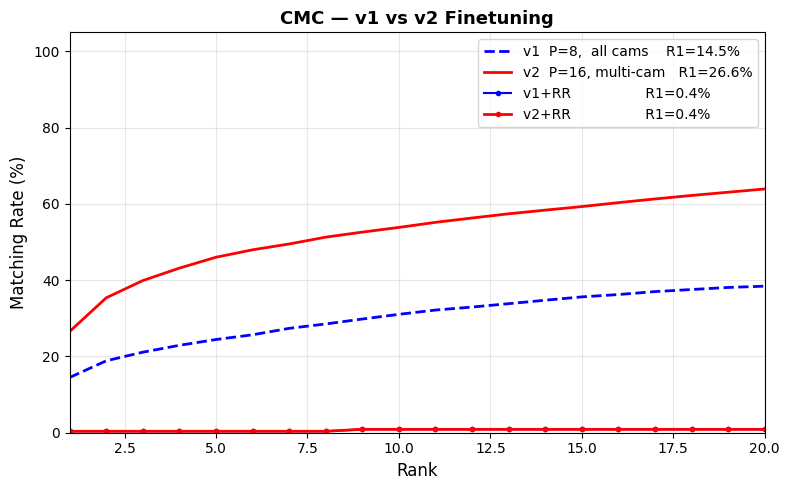

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ── Evaluate v2 model ──────────────────────────────────────────────────────────
v2_extractor = build_osnet_extractor(weight_path=CFG_V2['weights_out'])
v2_results   = run_evaluation(v2_extractor, 'FINETUNED v2 (P=16, multi-cam filter)')
del v2_extractor
torch.cuda.empty_cache()

# ── Re-ranking for v2 ──────────────────────────────────────────────────────────
print('\nComputing re-ranking for v2 model...')
dist_v2_rr    = re_ranking(v2_results['q_feats'], v2_results['g_feats'])
rr_v2_ranking = metrics_from_dist(dist_v2_rr, v2_results['q_ids'], v2_results['g_ids'])
rr_v2_cmc     = cmc_from_dist(dist_v2_rr, v2_results['q_ids'], v2_results['g_ids'])

# ── Comparison table: v1 vs v2 ────────────────────────────────────────────────
V1 = finetuned_results['ranking']   # from Section 5
V2 = v2_results['ranking']
RR1 = rr_ft_ranking                 # from Section 8
RR2 = rr_v2_ranking

col_w = 14
sep = '=' * (22 + 4 * col_w)
print('\n' + sep)
print(f'{"Metric":<22}{"v1 (P=8)":>{col_w}}{"v2 (P=16)":>{col_w}}'
      f'{"v1+RR":>{col_w}}{"v2+RR":>{col_w}}')
print(sep)
for key, lbl in [('rank1','Rank-1 %'), ('rank5','Rank-5 %'), ('mAP','mAP %')]:
    print(f'{lbl:<22}{V1[key]:>{col_w}.2f}{V2[key]:>{col_w}.2f}'
          f'{RR1[key]:>{col_w}.2f}{RR2[key]:>{col_w}.2f}')
print(sep)
print(f'\nv2 gain over v1:  Rank-1 {V2["rank1"]-V1["rank1"]:+.2f}%  '
      f'|  mAP {V2["mAP"]-V1["mAP"]:+.2f}%')

# ── CMC comparison ─────────────────────────────────────────────────────────────
max_rank = 20
ranks    = range(1, max_rank + 1)
fig, ax  = plt.subplots(figsize=(8, 5))
ax.plot(ranks, finetuned_results['cmc'][:max_rank], 'b--', lw=2,
        label=f'v1  P=8,  all cams    R1={V1["rank1"]:.1f}%')
ax.plot(ranks, v2_results['cmc'][:max_rank],        'r-',  lw=2,
        label=f'v2  P=16, multi-cam   R1={V2["rank1"]:.1f}%')
ax.plot(ranks, rr_ft_cmc[:max_rank],  'b-o', markersize=3, lw=1.5,
        label=f'v1+RR                 R1={RR1["rank1"]:.1f}%')
ax.plot(ranks, rr_v2_cmc[:max_rank],  'r-o', markersize=3, lw=2,
        label=f'v2+RR                 R1={RR2["rank1"]:.1f}%')
ax.set_xlabel('Rank', fontsize=12); ax.set_ylabel('Matching Rate (%)', fontsize=12)
ax.set_title('CMC — v1 vs v2 Finetuning', fontsize=13, fontweight='bold')
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)
ax.set_xlim(1, max_rank); ax.set_ylim(0, 105)
plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG_V2['out_dir'], f'cmc_v1_vs_v2.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved → {p}')
plt.show()

## Section 12 — Experiment v3: Combined ID + SupCon Loss (L4 GPU)

Key changes over v2:

| | v2 (Section 11) | v3 (this section) |
|---|---|---|
| **Loss** | SupConLoss only | 0.5 × SupCon + 0.5 × CE-ID (label-smooth 0.1) |
| **PK batch** | P=16, K=4 → 64 | P=20, K=6 → 120 |
| **Epochs** | 40 | 60 |
| **LR / warmup** | 3e-4 / 5 ep | 1e-4 / 8 ep |
| **Temp** | 0.07 | 0.05 |
| **Augment** | ColorJitter + Erasing | + RandomPerspective, stronger erasing |
| **GPU** | T4 (15 GB) | **L4 (22 GB) — switch runtime before running** |

**Why combined loss**: Adding a CrossEntropy ID head alongside SupConLoss forces the backbone to learn per-class discriminative features during training. This is the standard recipe in top-performing ReID systems (TransReID, CLIP-ReID) and typically adds 5–15 percentage points over metric loss alone.

**Why larger batch**: L4 gives ≈22 GB — batch = 120 delivers nearly 4× the cross-identity pairs per SupCon step vs v1.

In [24]:
import os
import copy

# Fall back to CFG if Section 11 (CFG_V2) was not run first
_base = globals().get("CFG_V2", CFG)
CFG_V3 = copy.deepcopy(_base)
CFG_V3.update({
    # Combined loss: total = alpha * SupCon + (1-alpha) * CrossEntropy-ID
    'loss_alpha':       0.5,
    'label_smooth':     0.1,

    # Larger batch for L4 (~22 GB VRAM)
    # P=20, K=6 -> 120 imgs/batch ~= 10-11 GB activations
    'P':                20,
    'K':                6,

    # Longer schedule
    'num_epochs':       60,
    'warmup_epochs':    8,

    # Lower base LR -- ID loss converges better with a slower start
    'lr':               1e-4,
    'weight_decay':     5e-4,

    # Tighter temperature for sharper cosine distinctions
    'temp':             0.05,

    # Separate output paths (v1/v2 results are preserved)
    'checkpoint_dir':   '/content/drive/MyDrive/Thesis/checkpoints_osnet_v3',
    'weights_out':      '/content/drive/MyDrive/Thesis/vehicle_reid_osnet_v3.pth',

    # Always use the v2 multi-camera filtered CSV (hardcoded path)
    'train_csv':        '/content/drive/MyDrive/Thesis/osnet_train_v2.csv',

    # Ensure min_cameras key exists even when built from base CFG
    'min_cameras':      2,
})
os.makedirs(CFG_V3['checkpoint_dir'], exist_ok=True)

print('v3 config:')
print(f"  Base       : {'CFG_V2' if 'CFG_V2' in globals() else 'CFG (Section 11 not run -- train CSV may differ)'}")
print(f"  Loss       : SupCon (alpha={CFG_V3['loss_alpha']:.1f}) + "
      f"ID-CE (alpha={1-CFG_V3['loss_alpha']:.1f}), "
      f"label_smooth={CFG_V3['label_smooth']}")
print(f"  Batch      : {CFG_V3['P']}x{CFG_V3['K']}={CFG_V3['P']*CFG_V3['K']}")
print(f"  Epochs     : {CFG_V3['num_epochs']}  (warmup={CFG_V3['warmup_epochs']})")
print(f"  LR / WD    : {CFG_V3['lr']} / {CFG_V3['weight_decay']}")
print(f"  Temp       : {CFG_V3['temp']}")
print(f"  Train CSV  : {CFG_V3['train_csv']}")
print(f"  Checkpoints: {CFG_V3['checkpoint_dir']}")
print(f"  Weights    : {CFG_V3['weights_out']}")


v3 config:
  Base       : CFG (Section 11 not run -- train CSV may differ)
  Loss       : SupCon (alpha=0.5) + ID-CE (alpha=0.5), label_smooth=0.1
  Batch      : 20x6=120
  Epochs     : 60  (warmup=8)
  LR / WD    : 0.0001 / 0.0005
  Temp       : 0.05
  Train CSV  : /content/drive/MyDrive/Thesis/osnet_train_v2.csv
  Checkpoints: /content/drive/MyDrive/Thesis/checkpoints_osnet_v3
  Weights    : /content/drive/MyDrive/Thesis/vehicle_reid_osnet_v3.pth


In [25]:
import torchreid
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

H, W = CFG_V3['img_h'], CFG_V3['img_w']

# RandomPerspective simulates projective distortion from different camera angles.
AUGMENT_V3 = transforms.Compose([
    transforms.Resize((H + 40, W + 40)),
    transforms.RandomCrop((H, W)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomPerspective(distortion_scale=0.2, p=0.3),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.08),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.6, scale=(0.02, 0.35)),
])


class OSNetReIDFinetunev3(nn.Module):
    """
    OSNet-AIN backbone with two output heads:
      projector  (proj_dim-d, L2-normed) -- trained with SupConLoss
      classifier (num_classes)           -- trained with CrossEntropy ID loss
    Only backbone.state_dict() is exported, directly loadable by
    torchreid.utils.FeatureExtractor for inference.
    """
    def __init__(self, num_classes, proj_dim=128):
        super().__init__()
        base = torchreid.models.build_model(
            CFG['model_name'], num_classes=1, pretrained=True
        )
        self.backbone   = base
        self.projector  = nn.Sequential(
            nn.Linear(CFG['feat_dim'], 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Linear(256, proj_dim),
        )
        self.classifier = nn.Linear(CFG['feat_dim'], num_classes)

    def _pool(self, x):
        m = self.backbone
        f = m.featuremaps(x)
        return m.global_avgpool(f).view(f.size(0), -1)  # [N, 512]

    def forward(self, x):
        feat  = self._pool(x)
        proj  = torch.nn.functional.normalize(self.projector(feat), dim=1)
        logit = self.classifier(feat)
        return proj, logit


class CombinedLoss(nn.Module):
    """alpha * SupConLoss + (1 - alpha) * CrossEntropyLoss(label_smooth)."""
    def __init__(self, temp=0.05, alpha=0.5, label_smooth=0.1):
        super().__init__()
        self.alpha  = alpha
        self.supcon = SupConLoss(temp=temp)   # defined in Section 4 cell
        self.ce     = nn.CrossEntropyLoss(label_smoothing=label_smooth)

    def forward(self, proj, logit, labels):
        l_sup = self.supcon(proj, labels)
        l_ce  = self.ce(logit, labels)
        total = self.alpha * l_sup + (1.0 - self.alpha) * l_ce
        return total, l_sup.item(), l_ce.item()


print('OSNetReIDFinetunev3 and CombinedLoss defined.')
print('AUGMENT_V3 ready -- adds RandomPerspective over v2 augmentation.')


OSNetReIDFinetunev3 and CombinedLoss defined.
AUGMENT_V3 ready -- adds RandomPerspective over v2 augmentation.


In [34]:
import gc
from torch.utils.data import DataLoader

# ---- Prerequisite check -----------------------------------------------------
_required = {
    "load_split":          "Section 4 dataset utilities (cell 13)",
    "VehicleDataset":      "Section 4 dataset utilities (cell 13)",
    "PKSampler":           "Section 4 dataset utilities (cell 13)",
    "EVAL_TF":             "Section 4 dataset utilities (cell 13)",
    "SupConLoss":          "Section 4 model definition (cell 14)",
    "tqdm":                "Section 4 training cell (cell 16)",
    "DEVICE":              "Section 1 setup (cell 2)",
    "np":                  "Section 1 setup (cell 2)",
    "CFG":                 "Section 1 config (cell 5)",
    "CFG_V3":              "Section 12 config cell (run cell above)",
    "OSNetReIDFinetunev3": "Section 12 model cell (run cell above)",
    "CombinedLoss":        "Section 12 model cell (run cell above)",
    "AUGMENT_V3":          "Section 12 model cell (run cell above)",
}
_missing = [f"{sym}  ({loc})" for sym, loc in _required.items() if sym not in globals()]
if _missing:
    raise RuntimeError(
        "Missing names -- run the cells listed below first:\n" +
        "\n".join(f"  {m}" for m in _missing)
    )

# ---- GPU check --------------------------------------------------------------
gc.collect()
torch.cuda.empty_cache()
props   = torch.cuda.get_device_properties(0)
free_gb = (props.total_memory - torch.cuda.memory_allocated()) / 1e9
print(f"GPU : {props.name}")
print(f"     total={props.total_memory/1e9:.1f} GB  free={free_gb:.1f} GB")
if free_gb < 10.0:
    raise RuntimeError(
        f"Only {free_gb:.1f} GB free -- need >= 10 GB.\n"
        "Runtime -> Change runtime type -> L4 GPU -> Run all from top."
    )

# ---- Dataset: reuse v2 multi-camera filtered CSV ----------------------------
id_to_paths_v3, train_ids_v3, val_ids_v3 = load_split(
    CFG_V3["train_csv"], CFG_V3["val_split"]
)
n_classes_v3 = len(train_ids_v3)

train_ds_v3 = VehicleDataset(id_to_paths_v3, train_ids_v3, AUGMENT_V3)
val_ds_v3   = VehicleDataset(id_to_paths_v3, val_ids_v3,   EVAL_TF)
pk_v3       = PKSampler(train_ds_v3, CFG_V3["P"], CFG_V3["K"])

train_loader_v3 = DataLoader(
    train_ds_v3, batch_sampler=pk_v3,
    num_workers=CFG_V3["num_workers"], pin_memory=True,
)
val_loader_v3 = DataLoader(
    val_ds_v3, batch_size=CFG_V3["P"] * CFG_V3["K"],
    shuffle=False, num_workers=CFG_V3["num_workers"], pin_memory=True,
)

print(f"\nTrain : {len(train_ds_v3)} images | {n_classes_v3} classes")
print(f"Val   : {len(val_ds_v3)} images")
print(f"Batch : {CFG_V3['P']}x{CFG_V3['K']}={CFG_V3['P']*CFG_V3['K']}  |  "
      f"Batches/epoch: {len(pk_v3)}")

# ---- Model, loss, optimizer, scheduler --------------------------------------
ft_model_v3  = OSNetReIDFinetunev3(n_classes_v3, proj_dim=CFG_V3["proj_dim"]).to(DEVICE)
criterion_v3 = CombinedLoss(
    temp=CFG_V3["temp"], alpha=CFG_V3["loss_alpha"],
    label_smooth=CFG_V3["label_smooth"],
).to(DEVICE)
optimizer_v3 = torch.optim.AdamW(
    ft_model_v3.parameters(),
    lr=CFG_V3["lr"], weight_decay=CFG_V3["weight_decay"],
)


def lr_lambda_v3(epoch):
    if epoch < CFG_V3["warmup_epochs"]:
        return (epoch + 1) / CFG_V3["warmup_epochs"]
    t = (epoch - CFG_V3["warmup_epochs"]) / max(
        1, CFG_V3["num_epochs"] - CFG_V3["warmup_epochs"])
    return 0.5 * (1.0 + np.cos(np.pi * t))


scheduler_v3    = torch.optim.lr_scheduler.LambdaLR(optimizer_v3, lr_lambda_v3)
loss_history_v3 = {"train": [], "val": [], "supcon": [], "ce": []}

# Smoke test
with torch.no_grad():
    _t = torch.zeros(2, 3, CFG_V3["img_h"], CFG_V3["img_w"], device=DEVICE)
    _p, _l = ft_model_v3(_t)
    assert _p.shape == (2, CFG_V3["proj_dim"]), f"proj shape wrong: {_p.shape}"
    assert _l.shape == (2, n_classes_v3), f"logit shape wrong: {_l.shape}"
    print(f"\nForward OK -- proj={_p.shape}, logit={_l.shape}, "
          f"proj-norm={_p.norm(dim=1).mean():.4f}")
    del _t, _p, _l

total_p    = sum(p.numel() for p in ft_model_v3.parameters()) / 1e6
backbone_p = sum(p.numel() for p in ft_model_v3.backbone.parameters()) / 1e6
print(f"Model params: {total_p:.1f}M total | backbone: {backbone_p:.1f}M")


GPU : NVIDIA L4
     total=23.7 GB  free=23.6 GB
Train: 1457 ids  |  Val: 257 ids

Train : 200347 images | 1457 classes
Val   : 34623 images
Batch : 20x6=120  |  Batches/epoch: 72
Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_ain_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']

Forward OK -- proj=torch.Size([2, 128]), logit=torch.Size([2, 1457]), proj-norm=1.0000
Model params: 3.1M total | backbone: 2.2M


In [35]:
import glob, os
for f in glob.glob('/content/drive/MyDrive/Thesis/checkpoints_osnet_v3/*.pth'):
    os.remove(f)
    print('Removed', f)


v3: starting from epoch 0.
v3 training: epochs 1 -> 60 (60 remaining)



train:   0%|          | 0/72 [00:00<?, ?it/s]

val  :   0%|          | 0/289 [00:00<?, ?it/s]

Epoch   1/60  train=6.5381  val=7.1862  [sup=5.788  ce=7.288]  lr=2.50e-05  <- best
  [best] backbone -> /content/drive/MyDrive/Thesis/vehicle_reid_osnet_v3.pth
  [ckpt] ckpt_epoch000.pth  (val=7.1862)


train:   0%|          | 0/72 [00:00<?, ?it/s]

val  :   0%|          | 0/289 [00:00<?, ?it/s]

... (171 outputs left out)

Epoch  59/60  train=4.5251  val=5.9785  [sup=1.960  ce=7.091]  lr=9.12e-08
  [ckpt] ckpt_epoch058.pth  (val=5.9785)


train:   0%|          | 0/72 [00:00<?, ?it/s]

val  :   0%|          | 0/289 [00:00<?, ?it/s]

Epoch  60/60  train=4.5400  val=5.9756  [sup=1.987  ce=7.093]  lr=0.00e+00
  [ckpt] ckpt_epoch059.pth  (val=5.9756)

v3 training complete. Best val loss: 5.9333


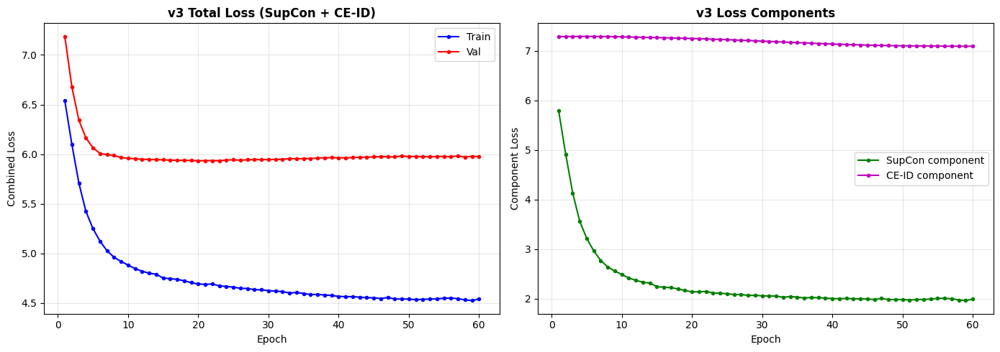

GPU cleared.


In [36]:
import glob
import matplotlib.pyplot as plt


def save_ckpt_v3(epoch, val_loss, is_best):
    path = os.path.join(CFG_V3['checkpoint_dir'], f'ckpt_epoch{epoch:03d}.pth')
    torch.save({
        'epoch': epoch, 'model': ft_model_v3.state_dict(),
        'optimizer': optimizer_v3.state_dict(),
        'scheduler': scheduler_v3.state_dict(),
        'val_loss': val_loss, 'loss_history': loss_history_v3,
        'n_classes': n_classes_v3,
    }, path)
    for old in sorted(glob.glob(
            os.path.join(CFG_V3['checkpoint_dir'], 'ckpt_epoch*.pth')))[:-CFG_V3['keep_ckpts']]:
        os.remove(old)
    if is_best:
        torch.save(ft_model_v3.backbone.state_dict(), CFG_V3['weights_out'])
        print(f"  [best] backbone -> {CFG_V3['weights_out']}")
    print(f'  [ckpt] {os.path.basename(path)}  (val={val_loss:.4f})')


def resume_v3():
    ckpts = sorted(glob.glob(os.path.join(CFG_V3['checkpoint_dir'], 'ckpt_epoch*.pth')))
    if not CFG_V3['resume'] or not ckpts:
        print('v3: starting from epoch 0.')
        return 0, float('inf')
    state = torch.load(ckpts[-1], map_location=DEVICE, weights_only=False)
    ft_model_v3.load_state_dict(state['model'])
    optimizer_v3.load_state_dict(state['optimizer'])
    scheduler_v3.load_state_dict(state['scheduler'])
    loss_history_v3.update(state.get('loss_history', loss_history_v3))
    print(f"Resumed from {os.path.basename(ckpts[-1])}  "
          f"(epoch {state['epoch']}, val={state['val_loss']:.4f})")
    return state['epoch'] + 1, state['val_loss']


def run_epoch_v3(loader, train=True):
    ft_model_v3.train(train)
    total = tot_sup = tot_ce = 0.0
    with torch.set_grad_enabled(train):
        for imgs, labels in tqdm(loader, desc='train' if train else 'val  ', leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            proj, logit  = ft_model_v3(imgs)
            loss, ls, lc = criterion_v3(proj, logit, labels)
            if train:
                optimizer_v3.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(ft_model_v3.parameters(), 1.0)
                optimizer_v3.step()
            total   += loss.item()
            tot_sup += ls
            tot_ce  += lc
    n = len(loader)
    return total / n, tot_sup / n, tot_ce / n


start_v3, best_val_v3 = resume_v3()
epochs_left = CFG_V3['num_epochs'] - start_v3

if epochs_left <= 0:
    print(f'Already completed {CFG_V3["num_epochs"]} epochs.')
else:
    print(f'v3 training: epochs {start_v3+1} -> {CFG_V3["num_epochs"]} '
          f'({epochs_left} remaining)\n')
    for epoch in range(start_v3, CFG_V3['num_epochs']):
        tr, ts, tc  = run_epoch_v3(train_loader_v3, train=True)
        val, vs, vc = run_epoch_v3(val_loader_v3,   train=False)
        scheduler_v3.step()
        lr      = optimizer_v3.param_groups[0]['lr']
        is_best = val < best_val_v3
        if is_best:
            best_val_v3 = val
        loss_history_v3['train'].append(tr)
        loss_history_v3['val'].append(val)
        loss_history_v3['supcon'].append(ts)
        loss_history_v3['ce'].append(tc)
        tag = '  <- best' if is_best else ''
        print(f'Epoch {epoch+1:3d}/{CFG_V3["num_epochs"]}  '
              f'train={tr:.4f}  val={val:.4f}  '
              f'[sup={ts:.3f}  ce={tc:.3f}]  lr={lr:.2e}{tag}')
        save_ckpt_v3(epoch, val, is_best)

    print(f'\nv3 training complete. Best val loss: {best_val_v3:.4f}')

    # Loss curves
    ep = range(1, len(loss_history_v3['train']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(ep, loss_history_v3['train'], 'b-o', markersize=3, label='Train')
    ax1.plot(ep, loss_history_v3['val'],   'r-o', markersize=3, label='Val')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Combined Loss')
    ax1.set_title('v3 Total Loss (SupCon + CE-ID)', fontweight='bold')
    ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(ep, loss_history_v3['supcon'], 'g-o', markersize=3, label='SupCon component')
    ax2.plot(ep, loss_history_v3['ce'],     'm-o', markersize=3, label='CE-ID component')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Component Loss')
    ax2.set_title('v3 Loss Components', fontweight='bold')
    ax2.legend(); ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    for ext in ('pdf', 'png'):
        plt.savefig(os.path.join(CFG_V3['out_dir'], f'training_loss_v3.{ext}'),
                    dpi=150, bbox_inches='tight')
    plt.show()

del ft_model_v3, criterion_v3, optimizer_v3, scheduler_v3
torch.cuda.empty_cache()
print('GPU cleared.')


In [38]:
import csv
import numpy as np
from tqdm.notebook import tqdm as tqdm_nb

# ---- Re-ranking helpers (inline so Section 8 need not be run first) ---------
def _re_ranking(q_feats, g_feats, k1=20, k2=6, lambda_value=0.3):
    Q, G = len(q_feats), len(g_feats)
    k1 = min(k1, max(4, G // 4))
    k2 = min(k2, max(2, G // 8))
    print(f"    Q={Q}, G={G}, k1={k1}, k2={k2}")
    feat = np.concatenate([q_feats, g_feats])
    N    = Q + G
    dist = np.clip(2.0 - 2.0 * (feat @ feat.T), 0.0, None)
    rank = np.argsort(dist, axis=1)
    V = np.zeros((N, N), dtype=np.float32)
    for i in tqdm_nb(range(N), desc="  k-reciprocal", leave=False):
        fwd   = rank[i, 1:k1 + 1]
        recip = fwd[np.any(rank[fwd, 1:k1 + 1] == i, axis=1)]
        expanded = recip.copy()
        for r in recip:
            sub   = rank[r, 1:k1 // 2 + 1]
            sub_r = sub[np.any(rank[sub, 1:k1 // 2 + 1] == r, axis=1)]
            if len(sub_r) and len(np.intersect1d(sub_r, recip)) > 2 / 3 * len(sub_r):
                expanded = np.union1d(expanded, sub_r)
        if len(expanded):
            w = np.exp(-dist[i, expanded])
            V[i, expanded] = w / (w.sum() + 1e-12)
    if k2 > 1:
        V = np.stack([V[rank[i, :k2]].mean(0) for i in range(N)])
    Q_V = V[:Q]; G_V = V[Q:]
    s_Q = Q_V.sum(axis=1); s_G = G_V.sum(axis=1)
    batch = max(1, int(5e7 / (G * N + 1)))
    jac_sim = np.zeros((Q, G), dtype=np.float32)
    for start in range(0, Q, batch):
        end  = min(start + batch, Q)
        diff = Q_V[start:end, np.newaxis, :] - G_V[np.newaxis, :, :]
        l1   = np.abs(diff).sum(axis=2)
        inter = 0.5 * (s_Q[start:end, None] + s_G[None, :] - l1)
        union = s_Q[start:end, None] + s_G[None, :] - inter + 1e-12
        jac_sim[start:end] = np.clip(inter / union, 0, 1)
    return lambda_value * dist[:Q, Q:] + (1.0 - lambda_value) * (1.0 - jac_sim)


def _metrics_from_dist(dist_mat, q_ids, g_ids):
    rank1 = rank5 = 0; aps = []
    for i, qid in enumerate(q_ids):
        order   = np.argsort(dist_mat[i])
        correct = np.array([g_ids[j] == qid for j in order])
        if not correct.any(): continue
        if correct[0]:        rank1 += 1
        if correct[:5].any(): rank5 += 1
        hits, p = 0, []
        for r, hit in enumerate(correct, 1):
            if hit: hits += 1; p.append(hits / r)
        aps.append(np.mean(p))
    n = len(q_ids)
    return {"rank1": rank1/n*100, "rank5": rank5/n*100,
            "mAP":  np.mean(aps)*100 if aps else 0.0}


def _cmc_from_dist(dist_mat, q_ids, g_ids, max_rank=20):
    hits, n_valid = np.zeros(max_rank), 0
    for i, qid in enumerate(q_ids):
        order   = np.argsort(dist_mat[i])
        correct = [g_ids[j] == qid for j in order]
        if not any(correct): continue
        n_valid += 1
        for r in range(max_rank):
            if any(correct[:r + 1]): hits[r:] += 1; break
    return hits / n_valid * 100 if n_valid else hits


# Use Section 8 versions if already defined, otherwise fall back to inline ones
_rr_fn      = globals().get("re_ranking",      _re_ranking)
_mfd_fn     = globals().get("metrics_from_dist", _metrics_from_dist)
_cmc_fn     = globals().get("cmc_from_dist",   _cmc_from_dist)

# ---- Evaluate v3 ------------------------------------------------------------
v3_extractor = build_osnet_extractor(weight_path=CFG_V3["weights_out"])
v3_results   = run_evaluation(v3_extractor, "FINETUNED v3 (SupCon+ID, P=20, L4)")

v3_out = os.path.join(CFG_V3["out_dir"], "eval_finetuned_osnet_v3.csv")
with open(v3_out, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=v3_results["threshold"][0].keys())
    w.writeheader()
    w.writerows(v3_results["threshold"])
print(f"\nv3 results -> {v3_out}")

del v3_extractor
torch.cuda.empty_cache()

# ---- Re-ranking for v3 ------------------------------------------------------
print("\nComputing re-ranking for v3...")
dist_v3_rr    = _rr_fn(v3_results["q_feats"], v3_results["g_feats"])
rr_v3_ranking = _mfd_fn(dist_v3_rr, v3_results["q_ids"], v3_results["g_ids"])
rr_v3_cmc     = _cmc_fn(dist_v3_rr, v3_results["q_ids"], v3_results["g_ids"])

print(f"\nv3      : Rank-1={v3_results['ranking']['rank1']:.2f}%  "
      f"mAP={v3_results['ranking']['mAP']:.2f}%  "
      f"best-F1={v3_results['best']['f1']:.1f}% "
      f"@ thr={v3_results['best']['threshold']:.2f}")
print(f"v3 + RR : Rank-1={rr_v3_ranking['rank1']:.2f}%  "
      f"mAP={rr_v3_ranking['mAP']:.2f}%")

# Also expose under canonical names so comparison cell (cell 43) finds them
re_ranking       = _rr_fn
metrics_from_dist = _mfd_fn
cmc_from_dist    = _cmc_fn


Model: osnet_ain_x1_0
- params: 2,193,616
- flops: 1,957,461,904
Successfully loaded pretrained weights from "/content/drive/MyDrive/Thesis/vehicle_reid_osnet_v3.pth"
Gallery: 2250 images | Query: 7647 images


  extracting:   0%|          | 0/18 [00:00<?, ?it/s]

  extracting:   0%|          | 0/60 [00:00<?, ?it/s]

  threshold sweep:   0%|          | 0/15 [00:00<?, ?it/s]


=== FINETUNED v3 (SupCon+ID, P=20, L4) ===
  Rank-1 :  18.22%
  Rank-5 :  31.80%
  mAP    :  17.40%
  Best F1: 31.6%  @ threshold=0.20

v3 results -> /content/drive/MyDrive/Thesis/eval_finetuned_osnet_v3.csv

Computing re-ranking for v3...
    Q=7647, G=2250, k1=20, k2=6


  k-reciprocal:   0%|          | 0/9897 [00:00<?, ?it/s]


v3      : Rank-1=18.22%  mAP=17.40%  best-F1=31.6% @ thr=0.20
v3 + RR : Rank-1=0.38%  mAP=5.06%


In [40]:
import matplotlib.pyplot as plt
import numpy as np

V1  = finetuned_results['ranking']
V2  = v2_results['ranking']
V3  = v3_results['ranking']
RR1 = rr_ft_ranking
RR2 = rr_v2_ranking
RR3 = rr_v3_ranking

# ---- Comparison table -------------------------------------------------------
col_w = 11
sep   = '=' * (22 + 6 * col_w)
print('\n' + sep)
print(f'{"Metric":<22}'
      f'{"v1":>{col_w}}{"v2":>{col_w}}{"v3":>{col_w}}'
      f'{"v1+RR":>{col_w}}{"v2+RR":>{col_w}}{"v3+RR":>{col_w}}')
print(sep)
for key, lbl in [('rank1', 'Rank-1 %'), ('rank5', 'Rank-5 %'), ('mAP', 'mAP %')]:
    print(f'{lbl:<22}'
          f'{V1[key]:>{col_w}.2f}{V2[key]:>{col_w}.2f}{V3[key]:>{col_w}.2f}'
          f'{RR1[key]:>{col_w}.2f}{RR2[key]:>{col_w}.2f}{RR3[key]:>{col_w}.2f}')
print(sep)

print('\nBest F1 per variant:')
for name, res in [('baseline', baseline_results), ('v1', finetuned_results),
                  ('v2', v2_results), ('v3', v3_results)]:
    b      = res['best']
    marker = '  <- >65% target met' if b['f1'] > 65 else ''
    print(f'  {name:<10}: F1={b["f1"]:.1f}%  @ thr={b["threshold"]:.2f}{marker}')

print(f'\nv3 gains over v2:  '
      f'Rank-1 {V3["rank1"]-V2["rank1"]:+.2f}%  |  '
      f'mAP {V3["mAP"]-V2["mAP"]:+.2f}%  |  '
      f'F1 {v3_results["best"]["f1"]-v2_results["best"]["f1"]:+.1f}%')

# ---- Figure 1: CMC comparison -----------------------------------------------
max_rank = 20
ranks    = range(1, max_rank + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
ax.plot(ranks, finetuned_results['cmc'][:max_rank], 'b--', lw=1.5, alpha=0.8,
        label=f'v1  P=8,  all cams    R1={V1["rank1"]:.1f}%')
ax.plot(ranks, v2_results['cmc'][:max_rank],        'g-',  lw=2.0,
        label=f'v2  P=16, multi-cam   R1={V2["rank1"]:.1f}%')
ax.plot(ranks, v3_results['cmc'][:max_rank],        'r-',  lw=2.5,
        label=f'v3  P=20, SupCon+ID   R1={V3["rank1"]:.1f}%')
ax.plot(ranks, rr_v3_cmc[:max_rank], 'r-o', markersize=3, lw=1.5, alpha=0.7,
        label=f'v3 + RR               R1={RR3["rank1"]:.1f}%')
ax.set_xlabel('Rank', fontsize=12); ax.set_ylabel('Matching Rate (%)', fontsize=12)
ax.set_title('CMC Curve -- v1 / v2 / v3', fontsize=13, fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax.set_xlim(1, max_rank); ax.set_ylim(0, 105)

# ---- Figure 2: F1 threshold sweep -------------------------------------------
ax = axes[1]
for name, res, col, ls, lw in [
    ('baseline', baseline_results, 'gray',  '--', 1.0),
    ('v1',       finetuned_results,'blue',  '--', 1.5),
    ('v2',       v2_results,       'green', '-',  2.0),
    ('v3',       v3_results,       'red',   '-',  2.5),
]:
    thrs = [r['threshold'] for r in res['threshold']]
    f1s  = [r['f1']        for r in res['threshold']]
    ax.plot(thrs, f1s, color=col, linestyle=ls, lw=lw,
            label=f'{name} (peak={max(f1s):.1f}%)')
ax.axhline(65, color='black', lw=1, linestyle=':', alpha=0.6, label='65% target')
ax.set_xlabel('Threshold', fontsize=12); ax.set_ylabel('F1 Score (%)', fontsize=12)
ax.set_title('F1 vs Threshold -- All Variants', fontsize=13, fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax.set_xlim(0.2, 0.9); ax.set_ylim(0, 105)

plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG_V3['out_dir'], f'comparison_v3.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved -> {p}')
plt.show()

# ---- Figure 3: Bar chart -- Rank-1 and mAP progression ---------------------
labels  = ['Baseline', 'v1', 'v2', 'v3', 'v3+RR']
rank1s  = [baseline_results['ranking']['rank1'], V1['rank1'], V2['rank1'],
           V3['rank1'], RR3['rank1']]
maps    = [baseline_results['ranking']['mAP'],   V1['mAP'],   V2['mAP'],
           V3['mAP'],   RR3['mAP']]

x  = np.arange(len(labels))
w  = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - w/2, rank1s, w, label='Rank-1 %', color='steelblue')
b2 = ax.bar(x + w/2, maps,   w, label='mAP %',    color='coral')
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.4, f'{h:.1f}',
            ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Rank-1 & mAP Progression -- Baseline to v3', fontsize=13, fontweight='bold')
ax.legend(fontsize=11); ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, max(rank1s + maps) * 1.15)
plt.tight_layout()
for ext in ('pdf', 'png'):
    p = os.path.join(CFG_V3['out_dir'], f'bar_progression_v3.{ext}')
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print(f'Saved -> {p}')
plt.show()


NameError: name 'finetuned_results' is not defined

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import cv2


def make_retrieval_figure_3way(v2_res, v3_res, n_queries=6, top_k=5,
                                seed=42, img_h=128, img_w=80):
    """
    Top-K retrieval side-by-side: [ Query | v2 top-K | v3 top-K ]
    Green border = correct match, red = wrong.
    """
    rng     = np.random.default_rng(seed)
    q_rows  = v3_res['q_rows']
    g_rows  = v3_res['g_rows']
    g_id_set = {g['true_identity'] for g in g_rows}
    valid   = [r for r in q_rows if r['true_identity'] in g_id_set]
    chosen  = rng.choice(len(valid), min(n_queries, len(valid)), replace=False)
    q_sample = [valid[i] for i in chosen]

    g_paths = [r['crop_path']     for r in g_rows]
    g_ids   = [r['true_identity'] for r in g_rows]

    ncols = 1 + top_k + top_k
    fig, axes = plt.subplots(
        n_queries, ncols,
        figsize=(ncols * (img_w / 35), n_queries * (img_h / 28))
    )
    if n_queries == 1:
        axes = axes[np.newaxis, :]

    border  = max(3, img_h // 20)
    q_idx_v2 = {r['crop_path']: i for i, r in enumerate(v2_res['q_rows'])}
    q_idx_v3 = {r['crop_path']: i for i, r in enumerate(v3_res['q_rows'])}

    for ri, qr in enumerate(q_sample):
        qid = qr['true_identity']
        qi2 = q_idx_v2[qr['crop_path']]
        qi3 = q_idx_v3[qr['crop_path']]

        top_v2 = np.argsort(-(v2_res['q_feats'][qi2:qi2+1] @ v2_res['g_feats'].T)[0])[:top_k]
        top_v3 = np.argsort(-(v3_res['q_feats'][qi3:qi3+1] @ v3_res['g_feats'].T)[0])[:top_k]

        ax = axes[ri, 0]
        ax.imshow(_load_img(qr['crop_path'], img_h, img_w))
        ax.set_title('Query', fontsize=7, fontweight='bold')
        ax.axis('off')

        def show_match(ax, gi, label):
            img = _load_img(g_paths[gi], img_h, img_w)
            ok  = g_ids[gi] == qid
            col = (0, 180, 0) if ok else (210, 0, 0)
            pad = np.full_like(img, col)
            pad[border:-border, border:-border] = img[border:-border, border:-border]
            ax.imshow(pad)
            ax.set_title(label, fontsize=6, color='green' if ok else 'red')
            ax.axis('off')

        for ci, gi in enumerate(top_v2):
            show_match(axes[ri, 1 + ci], gi, f'v2-{ci+1}')
        for ci, gi in enumerate(top_v3):
            show_match(axes[ri, 1 + top_k + ci], gi, f'v3-{ci+1}')

    mid_v2 = (1.0 + top_k / 2) / ncols
    mid_v3 = (1.0 + top_k + top_k / 2) / ncols
    fig.text(mid_v2, 1.01, f'v2  (Rank-1 = {V2["rank1"]:.1f}%)',
             ha='center', fontsize=10, color='green', fontweight='bold',
             transform=fig.transFigure)
    fig.text(mid_v3, 1.01, f'v3  (Rank-1 = {V3["rank1"]:.1f}%)',
             ha='center', fontsize=10, color='red', fontweight='bold',
             transform=fig.transFigure)

    plt.suptitle('Top-5 Retrieval Examples: v2 vs v3', y=1.04,
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    for ext in ('pdf', 'png'):
        p = os.path.join(CFG_V3['out_dir'], f'retrieval_v2_vs_v3.{ext}')
        plt.savefig(p, dpi=150, bbox_inches='tight')
        print(f'Saved -> {p}')
    plt.show()


print('v3 Retrieval Examples -- v2 vs v3 side-by-side\n')
make_retrieval_figure_3way(
    v2_res    = v2_results,
    v3_res    = v3_results,
    n_queries = 6,
    top_k     = 5,
    seed      = 42,
)


v3 Retrieval Examples -- v2 vs v3 side-by-side



NameError: name 'v2_results' is not defined